## Imports

In [1]:
import warnings
warnings.resetwarnings()
warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from itertools import combinations
from tqdm import tqdm

from scipy import stats, interp
from scipy.stats import ks_2samp, chi2

from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.multitest import multipletests

from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.feature_selection import SelectKBest, SelectPercentile, f_classif, mutual_info_classif, VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.datasets import make_classification
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold, LeaveOneOut,
    GridSearchCV, RandomizedSearchCV, cross_val_score, cross_val_predict,
    cross_validate, learning_curve, permutation_test_score
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, auc, precision_recall_curve,
    average_precision_score, mean_squared_error, r2_score, make_scorer,
    brier_score_loss, log_loss, matthews_corrcoef
)

from neuroHarmonize import harmonizationLearn, harmonizationApply
from adapt.instance_based import KMM
from tableone import TableOne

2026-08-19 09:45:34.023613: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-19 09:45:34.083996: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-19 09:45:41.319326: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## Utilities

In [3]:
def permutation_test_svm(X_all, y, models, scoring,
                         n_perm=1000,
                         primary_metric='roc_auc',
                         inner_splits=5, outer_splits=5,
                         cv_seed=42, random_state=42,
                         inner_n_jobs=-1):
    """

    The full procedure (PCA + variance threshold + SelectKBest + SVC grid search)
    is re-run from scratch on each label permutation, so the supervised feature
    selection cannot leak. Returns observed scores, p-values, and the null
    distributions for every metric in `scoring`.

    Treat `primary_metric` as the confirmatory test; the others are descriptive
    (or Bonferroni-correct across all of them).
    """
    rng = np.random.RandomState(random_state)
    y_arr = np.asarray(y)

    svm_pipeline = clone(models['SVM']['pipeline'])
    svm_pipeline.set_params(clf__probability=False)
    param_grid = models['SVM']['param_grid']

    inner_cv = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=cv_seed)
    outer_cv = StratifiedKFold(n_splits=outer_splits, shuffle=True, random_state=cv_seed)

    def nested_scores(y_target):
        grid = GridSearchCV(
            clone(svm_pipeline), param_grid,
            scoring=primary_metric,      # tune on the same objective as observed
            cv=inner_cv, n_jobs=inner_n_jobs,
        )
        res = cross_validate(
            grid, X_all, y_target,
            cv=outer_cv, scoring=scoring,
            n_jobs=1,                    # serial outer loop to avoid oversubscription
            return_estimator=False,
        )
        return {m: res[f'test_{m}'].mean() for m in scoring}

    # ---- Observed ----
    obs = nested_scores(y_arr)

    # ---- Null distribution ----
    perm = {m: np.empty(n_perm) for m in scoring}
    for i in tqdm(range(n_perm), desc="SVM permutation test"):
        s = nested_scores(rng.permutation(y_arr))
        for m in scoring:
            perm[m][i] = s[m]

    # ---- One-sided upper-tail p-values (all metrics are higher-is-better) ----
    pvals = {m: (np.sum(perm[m] >= obs[m]) + 1) / (n_perm + 1) for m in scoring}

    print("\n===== SVM nested-CV permutation test =====")
    print(f"Permutations: {n_perm}   tuned on: {primary_metric}\n")
    print(f"{'metric':<20}{'observed':>10}{'null mean':>12}{'p-value':>10}")
    for m in scoring:
        print(f"{m:<20}{obs[m]:>10.3f}{perm[m].mean():>12.3f}{pvals[m]:>10.4f}")
    print(f"\nConfirmatory test ({primary_metric}): p = {pvals[primary_metric]:.4f}")
    print("(Other metrics are descriptive; Bonferroni-correct if you want them all to count.)")

    return obs, pvals, perm


In [4]:
def combat_harmonize(df1: pd.DataFrame,
                     df2: pd.DataFrame,
                     log1p=False):
    """
    Harmonize df1 and df2 using neuroHarmonize ComBat (requires 'SITE' covariate).
    Returns harmonized df1_h, df2_h, and KS-report.
    """
    common = df1.columns.intersection(df2.columns)
    df1, df2 = df1[common].copy(), df2[common].copy()
    
    if log1p:
        safe_cols = [c for c in common if (df1[c] >= 0).all() and (df2[c] >= 0).all()]
        df1[safe_cols] = np.log1p(df1[safe_cols])
        df2[safe_cols] = np.log1p(df2[safe_cols])

    X = pd.concat([df1, df2], ignore_index=True)
    SITE = np.array(['df1']*len(df1) + ['df2']*len(df2))
    covars = pd.DataFrame({'SITE': SITE})  # <-- important name fix

    model, _ = harmonizationLearn(X.values, covars)
    X_h = harmonizationApply(X.values, covars, model)

    X_h = pd.DataFrame(X_h, columns=common)
    df1_h = X_h.iloc[:len(df1)].reset_index(drop=True)
    df2_h = X_h.iloc[len(df1):].reset_index(drop=True)

    diff_count = 0
    for col in common:
        stat, p = ks_2samp(df1_h[col], df2_h[col])
        if p < 0.05:
            diff_count += 1
    report = {
        'n_features': len(common),
        'diff_after': diff_count,
        'fraction_diff_after': diff_count / len(common)
    }

    return df1_h, df2_h, report


In [5]:
def plot_top_loadings(loadings, top_pcs,save_path, top_k):

    n = len(top_pcs)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5), sharey=False)  
    
    if n == 1:
        axes = [axes]

    for ax, pc in zip(axes, top_pcs):

        pc_index = pc - 1  
        pc_name  = loadings.columns[pc_index]

        # Top features
        top_features = loadings[pc_name].abs().sort_values(ascending=False).head(top_k).index
        top_weights  = loadings.loc[top_features, pc_name]

        ax.barh(top_features, top_weights.values)
        ax.axvline(0, linestyle="--", linewidth=1)

        ax.set_title(f"{pc_name} (Top {top_k})")
        ax.set_xlabel("Loading Weight")
        ax.set_ylabel("Feature")
    
    plt.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()

In [6]:
def permutation_significance_pca_svm_nested(X, y,
                                                 outer_splits=5,
                                                 n_perm=500,
                                                 scoring="balanced_accuracy",
                                                 random_state=42):
    # Base pipeline
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(random_state=random_state)),
        ('clf', SVC(kernel='rbf', probability=True, random_state=random_state))
    ])
    
    param_grid = {
        'clf__C': [10,50,75,100, 300, 1000],
        'clf__gamma': [0.002, 0.005, 0.01,0.05],
        'pca__n_components': [5, 10, 15,20,25,30]
    }

    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    outer_cv = StratifiedKFold(n_splits=outer_splits, shuffle=True, random_state=random_state)

    # GridSearchCV for nested CV
    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring=scoring,
        cv=inner_cv,
        n_jobs=-1
    )

    # ---- Compute observed score ----
    obs_scores = cross_val_score(search, X, y, cv=outer_cv, scoring=scoring, n_jobs=-1)
    score = np.mean(obs_scores)

    # ---- Permutation test ----
    perm_scores = []
    for i in tqdm(range(n_perm), desc="Permutation test"):
        y_perm = np.random.permutation(y)
        perm_cv_scores = cross_val_score(search, X, y_perm, cv=outer_cv, scoring=scoring, n_jobs=-1)
        perm_scores.append(np.mean(perm_cv_scores))
    perm_scores = np.array(perm_scores)

    # Compute p-value
    p_value = (np.sum(perm_scores >= score) + 1) / (n_perm + 1)

    print("\n===== Nested PCA+SVM Permutation Test =====")
    print(f"Observed {scoring}: {score:.3f}")
    print(f"Permutation p-value: {p_value:.4f}\n")

    return score, p_value, perm_scores

In [7]:
def permutation_significance_demo_nested(X_demo, y,
                                         outer_splits=5,
                                         n_perm=500,
                                         scoring="balanced_accuracy",
                                         random_state=42):

    # ---- SafeSelectKBest ----
    class SafeSelectKBest(BaseEstimator, TransformerMixin):
        def __init__(self, score_func=f_classif, k=10):
            self.score_func = score_func
            self.k = k

        def fit(self, X, y=None):
            self.selector_ = SelectKBest(
                score_func=self.score_func,
                k=min(self.k, X.shape[1])
            )
            self.selector_.fit(X, y)
            return self

        def transform(self, X):
            return self.selector_.transform(X)

        def get_support(self):
            return self.selector_.get_support()

    # ---- Pipeline ----
    pipe = Pipeline([
        ('var_thresh', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('select', SafeSelectKBest(score_func=f_classif)),
        ('clf', SVC(kernel='rbf', probability=True, random_state=random_state))
    ])

    param_grid = {
        'select__k': list(range(1, len(X_demo.columns) + 1)),
        'clf__C': [10, 100, 300, 1000],
        'clf__gamma': [0.001, 0.002, 0.05],
    }

    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    outer_cv = StratifiedKFold(n_splits=outer_splits, shuffle=True, random_state=random_state)

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_grid,
        n_iter=50,
        scoring=scoring,
        cv=inner_cv,
        n_jobs=-1,
        random_state=random_state
    )

    # ---- Observed score ----
    obs_scores = cross_val_score(search, X_demo, np.array(y), cv=outer_cv, scoring=scoring, n_jobs=-1)
    score = np.mean(obs_scores)

    # ---- Permutation test ----
    perm_scores = []
    for i in tqdm(range(n_perm), desc="Permutation test"):
        y_perm = np.random.permutation(np.array(y))
        perm_cv_scores = cross_val_score(search, X_demo, y_perm, cv=outer_cv, scoring=scoring, n_jobs=-1)
        perm_scores.append(np.mean(perm_cv_scores))

    perm_scores = np.array(perm_scores)
    p_value = (np.sum(perm_scores >= score) + 1) / (n_perm + 1)

    print("\n===== Nested Demo Permutation Test =====")
    print(f"Observed {scoring}: {score:.3f}")
    print(f"Permutation p-value: {p_value:.4f}\n")

    return score, p_value, perm_scores

In [8]:
def permutation_significance_rf_nested(X, y_bdi,
                                       outer_splits=5, n_perm=1000,
                                       scoring="balanced_accuracy",
                                       random_state=42):
    
    # Define pipeline with hyperparameter search
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(random_state=random_state)),
        ("rf", RandomForestClassifier(
            class_weight="balanced",
            n_jobs=-1,
            random_state=random_state
        ))
    ])
    
    # Hyperparameter grid
    param_grid = {
        'pca__n_components': [3, 5],
        'rf__n_estimators': [50, 100],
        'rf__max_depth': [3, 5],
        'rf__min_samples_split': [2, 5]
    }
    
    # Grid search will be performed in each CV fold
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)
    search = GridSearchCV(pipe, param_grid, cv=inner_cv, 
                         scoring=scoring, n_jobs=-1)
    
    # Outer CV for permutation test
    outer_cv = StratifiedKFold(n_splits=outer_splits, shuffle=True, 
                              random_state=random_state)
    
    score, perm_scores, p_value = permutation_test_score(
        search, X, y_bdi,
        cv=outer_cv,
        n_permutations=n_perm,
        scoring=scoring,
        n_jobs=-1,
        random_state=random_state
    )
    
    print(f"Observed {scoring}: {score:.3f}")
    print(f"Permutation p-value: {p_value:.4f}")
    
    return score, p_value, perm_scores

In [9]:
def decision_curve(y_true, y_pred_proba, thresholds=np.linspace(0.01, 0.99, 99)):
    y_true = np.array(y_true)
    y_pred_proba = np.array(y_pred_proba)

    results = {
        "Threshold": [],
        "NetBenefit_Model": [],
        "NetBenefit_All": [],
        "NetBenefit_None": []
    }

    for p_t in thresholds:
        # Predicted positives at threshold
        pred_pos = (y_pred_proba >= p_t).astype(int)

        TP = np.sum((pred_pos == 1) & (y_true == 1))
        FP = np.sum((pred_pos == 1) & (y_true == 0))
        N = len(y_true)

        # Net Benefit for the model
        if N > 0:
            net_benefit_model = (TP / N) - (FP / N) * (p_t / (1 - p_t))
        else:
            net_benefit_model = np.nan

        # Net Benefit for Treat-All strategy
        prevalence = np.mean(y_true)
        net_benefit_all = prevalence - (1 - prevalence) * (p_t / (1 - p_t))

        # Net Benefit for Treat-None strategy
        net_benefit_none = 0.0
        
        # Store results
        results["Threshold"].append(p_t)
        results["NetBenefit_Model"].append(net_benefit_model)
        results["NetBenefit_All"].append(net_benefit_all)
        results["NetBenefit_None"].append(net_benefit_none)

    return pd.DataFrame(results)

In [10]:
def get_top_features(loadings, pc_index=0, top_k=5):
    pc_name = loadings.columns[pc_index]
    top_features = loadings[pc_name].abs().sort_values(ascending=False).head(top_k).index
    top_weights = loadings.loc[top_features, pc_name]
    return top_features

In [11]:

# ============================================
# DCA with Calibrated Probabilities
# ============================================
def decision_curve_analysis(y_true, y_proba, thresholds=None):
    if thresholds is None:
        thresholds = np.linspace(0, 1, 100)
    
    net_benefit_model = []
    net_benefit_all = []
    
    for thresh in thresholds:
        y_pred = (y_proba >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        
        n = len(y_true)
        net_benefit = (tp / n) - (fp / n) * (thresh / (1 - thresh))
        net_benefit_model.append(net_benefit)
        
        tp_all = np.sum(y_true)
        fp_all = np.sum(1 - y_true)
        net_benefit_treat_all = (tp_all / n) - (fp_all / n) * (thresh / (1 - thresh))
        net_benefit_all.append(net_benefit_treat_all)
    
    return thresholds, net_benefit_model, net_benefit_all


In [12]:
def permutation_test_prospective(model, X_test, y_test, metric_fn, n_perm=1000, greater_is_better=True, random_state=42):
    rng = np.random.default_rng(random_state)

    # Real predictions
    if hasattr(model, "predict_proba"):
        y_pred = model.predict_proba(X_test)[:, 1]
    else:
        y_pred = model.predict(X_test)

    M_real = metric_fn(y_test, y_pred)

    perm_scores = np.zeros(n_perm)
    for i in range(n_perm):
        # shuffle rows of X relative to y
        perm_idx = rng.permutation(len(y_test))
        if hasattr(model, "predict_proba"):
            y_pred_perm = model.predict_proba(X_test.iloc[perm_idx])[:, 1]
        else:
            y_pred_perm = model.predict(X_test.iloc[perm_idx])
        perm_scores[i] = metric_fn(y_test, y_pred_perm)

    if greater_is_better:
        p_value = (1 + np.sum(perm_scores >= M_real)) / (n_perm + 1)
    else:
        p_value = (1 + np.sum(perm_scores <= M_real)) / (n_perm + 1)

    return M_real, perm_scores, p_value

## Data

In [13]:
Blossom = pd.read_csv('./data/BLOSSOM_formatted_data_for_prediction.csv')

In [14]:
Rest_Blossom = pd.read_csv('BLOSSOM_restingState_23-Nov-2024_nonZ.csv')

In [15]:
Blossom.head()

,id,age,bdi_1_1_bdi,bdi_1_12_bdi,bdi_2_12_bdi,bai_1_1_bai,bai_1_12_bai,bai_2_12_bai,msm,cgi_s_1_1_cgi,...,T6_Fp2_Gamma_WPPC,T6_Fz_Gamma_WPPC,T6_O1_Gamma_WPPC,T6_O2_Gamma_WPPC,T6_P3_Gamma_WPPC,T6_P4_Gamma_WPPC,T6_Pz_Gamma_WPPC,T6_T3_Gamma_WPPC,T6_T4_Gamma_WPPC,T6_T5_Gamma_WPPC
0,777,16,57.0,NaN,NaN,42.0,NaN,NaN,7,4,...,0.243310,0.049003,0.158750,0.651930,0.070219,0.67611,0.190110,0.010333,0.29956,0.028979
1,977,29,45.0,48.0,NaN,44.0,43.0,NaN,10,5,...,0.218850,0.219220,0.975350,0.229190,0.175310,0.43021,0.199650,0.257270,0.76989,0.296290
2,1415,32,12.0,2.0,5.0,8.0,3.0,2.0,6,3,...,0.959980,0.968050,0.883990,0.952390,0.968510,0.94651,0.974400,0.904550,0.93354,0.931950
3,1508,36,NaN,NaN,13.0,NaN,NaN,7.0,4,3,...,0.113090,0.220020,0.122590,0.007304,0.012410,0.47338,0.070241,0.001103,0.35743,0.023674
4,1671,58,NaN,NaN,NaN,NaN,NaN,NaN,9,4,...,0.027833,0.083740,0.052441,0.036340,0.032890,0.21364,0.038475,0.031680,0.12378,0.026606


In [16]:
np.unique(Rest_Blossom.Session)

array([1, 2, 3])

In [ ]:
Rest_Blossom = Rest_Blossom[Rest_Blossom['Session'] == 1]

In [17]:
Rest_Blossom['Subject'] = Rest_Blossom['Subject'].str.replace('sub-', '', regex=False)

In [18]:
Rest_Blossom = Rest_Blossom.rename(columns={'Subject': 'id'})

In [19]:
Blossom['id'] = Blossom['id'].astype(str)
Rest_Blossom['id'] = Rest_Blossom['id'].astype(str)

In [20]:
Rest_Blossom = Rest_Blossom.merge(Blossom[['id', 'bdi_responder']], on='id', how='left')

In [21]:
Rest_Blossom = Rest_Blossom.dropna(subset=['bdi_responder'])

In [22]:
Rest_Blossom = Rest_Blossom.copy()
Rest_Blossom['Channel'] = Rest_Blossom['Channel'].astype(str).str.strip().str.upper()
Rest_Blossom['FreqBand'] = Rest_Blossom['FreqBand'].astype(str).str.strip().str.capitalize()

Rest_Blossom['feature'] = Rest_Blossom['Channel'] + ' power ' + Rest_Blossom['FreqBand']

In [23]:
Rest_Blossom = Rest_Blossom.drop_duplicates(subset=['id', 'Channel', 'FreqBand'], keep='first')

In [24]:
Rest_Blossom = Rest_Blossom.pivot(index='id', columns='feature', values='Abs_Power')#.reset_index()

In [25]:
Rest_Blossom_remitter = Rest_Blossom.merge(Blossom[['id', 'bdi_remitter']], on='id', how='left')

In [26]:
y_remitt = Rest_Blossom_remitter.iloc[:,-1]

In [27]:
Rest_Blossom = Rest_Blossom.merge(Blossom[['id', 'bdi_responder']], on='id', how='left')

In [28]:
Blossom_tmp = Blossom[Blossom['id'].isin(Rest_Blossom['id'])].reset_index()

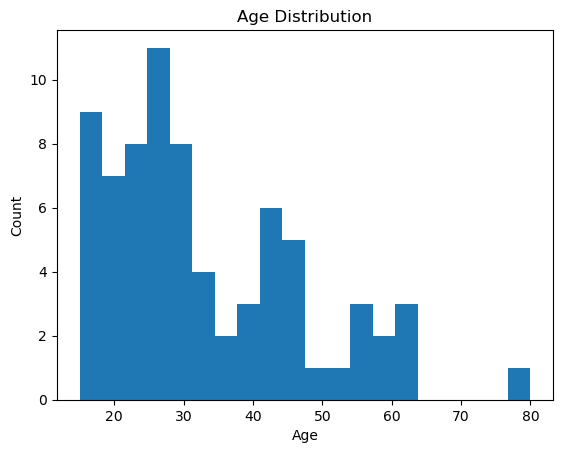

In [29]:
plt.figure()
plt.hist(Blossom_tmp.age, bins=20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.gca()
plt.show()

In [30]:
male_count = sum(Blossom_tmp.gender_M.values == 1)
female_count = sum(Blossom_tmp.gender_M == 0)

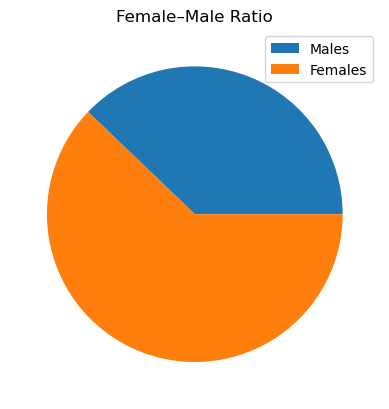

In [31]:
plt.figure()

plt.pie([male_count, female_count])

plt.title('Female–Male Ratio')
plt.legend(['Males', 'Females'])

plt.show()

In [32]:
Responding = sum(Blossom_tmp.bdi_responder.values == 1)
Not_Responding = sum(Blossom_tmp.bdi_responder.values == 0)

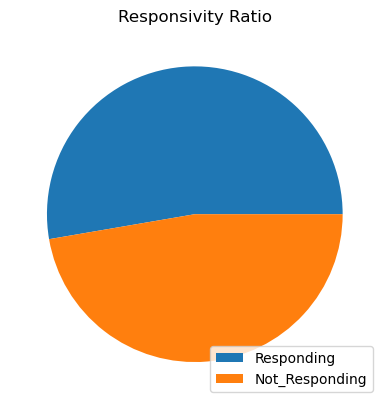

In [33]:
plt.figure()

plt.pie(
    [Responding, Not_Responding]
)

plt.title('Responsivity Ratio')
plt.legend(['Responding', 'Not_Responding'])

plt.show()

In [34]:
Responding/(Not_Responding+Responding)

0.527027027027027

In [35]:
Remitting = sum(Blossom_tmp.bdi_remitter.values == 1)
Non_Remitting = sum(Blossom_tmp.bdi_remitter.values == 0)

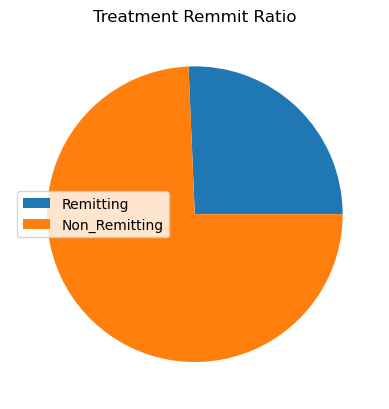

In [36]:
plt.pie([Remitting,Non_Remitting])
plt.title('Treatment Remmit Ratio')
plt.legend(['Remitting','Non_Remitting'])

In [37]:
Blossom_tmp.to_excel('Blossom_Completers.xlsx')

In [38]:
Blossom_tmp[[col for col in Blossom_tmp.columns if 'stimulation' in col]].sum()

tms_1_1_stimulation_site_1_Lt_DLPFC    51.0
tms_1_1_stimulation_site_1_Rt_DLPFC    21.0
tms_1_1_stimulation_site_2_Lt_M1        1.0
tms_1_1_stimulation_site_2_Lt_OFC       0.0
tms_1_1_stimulation_site_2_Pre.SMA      1.0
tms_1_1_stimulation_site_2_Rt_DLPFC    30.0
tms_1_1_stimulation_site_2_Rt_M1        0.0
tms_1_1_stimulation_site_2_Rt_OFC       1.0
dtype: float64

In [39]:
columns = ['age','gender_M', 'bdi_responder', 'bdi_1_1_bdi','bdi_1_12_bdi','bdi_2_12_bdi','tms_1_1_stimulation_site_1_Lt_DLPFC','tms_1_1_stimulation_site_1_Rt_DLPFC']      
categorical = ['gender_M','tms_1_1_stimulation_site_1_Lt_DLPFC','tms_1_1_stimulation_site_1_Rt_DLPFC']                             
groupby = 'bdi_responder'  

mytable = TableOne(data=Blossom_tmp,
                   columns=columns,
                   categorical=categorical,
                   groupby=groupby,
                   missing = False,
                   pval=True)

print(mytable.tabulate(tablefmt="fancy_grid"))

╒════════════════════════════════════════════╤════╤═════════════╤═════════════╤═════════════╤═══════════╕
│                                            │    │ Overall     │ 0.0         │ 1.0         │ P-Value   │
╞════════════════════════════════════════════╪════╪═════════════╪═════════════╪═════════════╪═══════════╡
│ n                                          │    │ 74          │ 35          │ 39          │           │
├────────────────────────────────────────────┼────┼─────────────┼─────────────┼─────────────┼───────────┤
│ age, mean (SD)                             │    │ 33.1 (14.3) │ 31.5 (15.3) │ 34.6 (13.3) │ 0.370     │
├────────────────────────────────────────────┼────┼─────────────┼─────────────┼─────────────┼───────────┤
│ gender_M, n (%)                            │ 0  │ 46 (62.2)   │ 21 (60.0)   │ 25 (64.1)   │ 0.902     │
├────────────────────────────────────────────┼────┼─────────────┼─────────────┼─────────────┼───────────┤
│                                            │

In [40]:
mytable.to_excel('Cohort_Char.xlsx')

## EEG Power Data

In [41]:
y_bdi  = Blossom_tmp.bdi_responder
indices = y_bdi.index
y_bdi = y_bdi.values
y_bdi = y_bdi.astype(bool)

In [42]:
X_power = Rest_Blossom.iloc[:,1:-1]

In [43]:
X_power = np.log1p(X_power)

In [44]:
np.sum(Blossom_tmp.bdi_1_1_bdi >= 10)

73

In [45]:
feature_names = X_power.columns

In [46]:
# ============================================
# Build a pipeline for any classifier
# ============================================
def make_pipeline(clf):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(random_state=42)),
        ('clf', clf)
    ])

# ============================================
# Model configurations
# ============================================
# Trimmed grid used by LR and RF only (for speed).
trimmed_pca_grid = {
    'pca__n_components': [5, 10, 20, 30],
}

models_eeg = {
    'SVM': {
        'pipeline': make_pipeline(SVC(kernel='rbf', probability=True, random_state=42)),
        'param_grid': {
            'pca__n_components': [5, 10, 15, 20, 25, 30],
            'clf__C': [10, 50, 75, 100, 300, 1000],
            'clf__gamma': [0.002, 0.005, 0.01, 0.05],
        }
    },
    'LogisticRegression': {
        'pipeline': make_pipeline(
            LogisticRegression(solver='liblinear', max_iter=5000, random_state=42)
        ),
        'param_grid': {
            **trimmed_pca_grid,
            'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'clf__penalty': ['l1', 'l2'],
        }
    },
    'RandomForest': {
        'pipeline': make_pipeline(
            RandomForestClassifier(random_state=42, n_jobs=1)
        ),
        'param_grid': {
            **trimmed_pca_grid,
            'clf__n_estimators': [300],
            'clf__max_depth': [None, 10],
            'clf__min_samples_split': [2, 5],
            'clf__max_features': ['sqrt'],
        }
    },
}

# ============================================
# CV setup + scoring
# ============================================
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'specificity': make_scorer(recall_score, pos_label=0)   # TN/(TN+FP)
}

# ============================================
# Nested CV across all models
# ============================================
all_results = {}

for name, cfg in models_eeg.items():
    print(f"\n>>> Running nested CV for {name}...")
    grid = GridSearchCV(
        cfg['pipeline'],
        cfg['param_grid'],
        scoring='roc_auc',
        cv=inner_cv,
        n_jobs=-1                       # inner: parallel
    )
    results = cross_validate(
        grid, X_power, y_bdi,
        cv=outer_cv, scoring=scoring,
        n_jobs=1,                       # outer: serial 
        return_train_score=False
    )
    all_results[name] = results

# ============================================
# Summary table
# ============================================
print("\n=== Nested Cross-Validation Results (EEG Power) ===\n")
summary_rows = []
for name, results in all_results.items():
    row = {'model': name}
    for metric in scoring.keys():
        scores = results[f'test_{metric}']
        row[metric] = f"{scores.mean():.3f} ± {scores.std():.3f}"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('model')
print(summary_df.to_string())


>>> Running nested CV for SVM...

>>> Running nested CV for LogisticRegression...

>>> Running nested CV for RandomForest...

=== Nested Cross-Validation Results (EEG Power) ===

                          roc_auc balanced_accuracy      precision         recall             f1    specificity
model                                                                                                          
SVM                 0.711 ± 0.162     0.623 ± 0.110  0.644 ± 0.087  0.618 ± 0.172  0.624 ± 0.130  0.629 ± 0.114
LogisticRegression  0.670 ± 0.113     0.636 ± 0.056  0.682 ± 0.094  0.643 ± 0.142  0.643 ± 0.074  0.629 ± 0.194
RandomForest        0.672 ± 0.170     0.662 ± 0.094  0.720 ± 0.159  0.696 ± 0.184  0.675 ± 0.102  0.629 ± 0.214


In [47]:

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(random_state=42)),
    ('clf', SVC(kernel='rbf', probability=True, random_state=42))
])

param_grid = {
    'clf__C': [10,50,75,100, 300, 1000],
    'clf__gamma': [0.002, 0.005, 0.01,0.05],
    'pca__n_components': [5, 10, 15,20,25,30]
}

# --------------------
# Cross-validation
# --------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --------------------
# Grid search
# --------------------
grid = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
grid.fit(X_power, y_bdi)

# --------------------
# Results
# --------------------
print(" Best parameters:", grid.best_params_)
print(f" Best cross-validated roc_auc: {grid.best_score_:.3f}")
# loadings = grid.best_estimator_.named_steps['pca'].components_.T  


 Best parameters: {'clf__C': 50, 'clf__gamma': 0.01, 'pca__n_components': 10}
 Best cross-validated roc_auc: 0.769


In [48]:
best_params = grid.best_params_


In [49]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(random_state=42)),
    ('clf', SVC(kernel='rbf', probability=True, random_state=42))
])

param_grid = {
    'clf__C': [10, 50, 75, 100, 300, 1000],
    'clf__gamma': [0.002, 0.005, 0.01, 0.05],
    'pca__n_components': [5, 10, 15, 20, 25, 30]
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=inner_cv, n_jobs=-1)

# Outer CV with multiple metrics
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'specificity': make_scorer(recall_score, pos_label=0)  # TN/(TN+FP) # ASK
}

results_eeg_final = cross_validate(
    grid,
    X_power,
    y_bdi,
    cv=outer_cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

print("\n=== Nested Cross-Validation Results ===")
for metric in scoring.keys():
    scores = results_eeg_final[f'test_{metric}']
    print(f"{metric:20s}: {scores.mean():.3f}")


=== Nested Cross-Validation Results ===
roc_auc             : 0.711
balanced_accuracy   : 0.623
precision           : 0.644
recall              : 0.618
f1                  : 0.624
specificity         : 0.629


In [50]:
grid

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('pca', PCA(random_state=42)),
                                       ('clf',
                                        SVC(probability=True,
                                            random_state=42))]),
             n_jobs=-1,
             param_grid={'clf__C': [10, 50, 75, 100, 300, 1000],
                         'clf__gamma': [0.002, 0.005, 0.01, 0.05],
                         'pca__n_components': [5, 10, 15, 20, 25, 30]},
             scoring='roc_auc')

In [51]:
def print_report(cv_results, scoring, confidence=0.95, baseline=0.5):
    ci_label = f"{int(confidence * 100)}% CI"
    print(f"\n=== Nested Cross-Validation Results (mean ± std, {ci_label}) ===")
    print(f"{'Metric':<22} {'Mean':>7}  {'Std':>7}  {'Min':>7}  {'Max':>7}  {ci_label:<22}  {'p-value':>8}")
    print("-" * 90)
    for metric in scoring.keys():
        arr = np.array(cv_results[f"test_{metric}"], dtype=float)
        n, mean = len(arr), arr.mean()
        std = float(np.std(arr, ddof=1))
        sem = float(stats.sem(arr))
        t_crit = stats.t.ppf((1 + confidence) / 2, df=n - 1)
        ci_low, ci_high = mean - t_crit * sem, mean + t_crit * sem
        _, p = stats.ttest_1samp(arr, popmean=baseline)
        sig = "**" if p < 0.01 else "*" if p < 0.05 else ""
        print(f"{metric:<22} {mean:>7.3f}  {std:>7.3f}  {arr.min():>7.3f}  {arr.max():>7.3f}"
              f"  [{ci_low:.3f}, {ci_high:.3f}]  {p:>8.4f} {sig}")
    print("-" * 90)
    print(f"p-value: one-sample t-test against baseline={baseline}  (* p<0.05, ** p<0.01)")

#### Analyzing the Principal Components

In [52]:
pipe_best_eeg = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(random_state=42)),
    ('clf', SVC(kernel='rbf', probability=True, random_state=42))
])

pipe_best_eeg.set_params(**best_params)
pipe_best_eeg.fit(X_power, y_bdi)


pca = pipe_best_eeg.named_steps["pca"]

loadings = pca.components_.T        
explained_variance = pca.explained_variance_ratio_

# Optional: PC names
pc_names = [f"PC{i+1}" for i in range(loadings.shape[1])]


X_scaled = pipe_best_eeg.named_steps["scaler"].transform(X_power)
X_pca = pca.transform(X_scaled)                 # (n_samples, n_components)

clf = pipe_best_eeg.named_steps["clf"]

def model_fn(data):
    return clf.predict_proba(data)[:, 1]

background = shap.sample(X_pca, 50, random_state=42)

explainer = shap.KernelExplainer(model_fn, background)

shap_values = explainer.shap_values(X_pca, nsamples=1000)

# Handle binary-class output
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap_values = np.asarray(shap_values)           # (n_samples, n_components)

  0%|          | 0/74 [00:00<?, ?it/s]

In [53]:
import pandas as pd

mean_abs_shap = np.abs(shap_values).mean(axis=0)   # (n_components,)

pc_importance = pd.DataFrame({
    "PC": pc_names,
    "mean_abs_shap": mean_abs_shap,
    "explained_variance_ratio": explained_variance,
}).sort_values("mean_abs_shap", ascending=False)

print(pc_importance)

     PC  mean_abs_shap  explained_variance_ratio
0   PC1       0.077418                  0.420596
3   PC4       0.063533                  0.045936
5   PC6       0.054914                  0.033750
8   PC9       0.049794                  0.017278
1   PC2       0.044109                  0.164961
2   PC3       0.043618                  0.081926
4   PC5       0.041390                  0.037520
9  PC10       0.036020                  0.016174
6   PC7       0.033598                  0.022488
7   PC8       0.028940                  0.019598


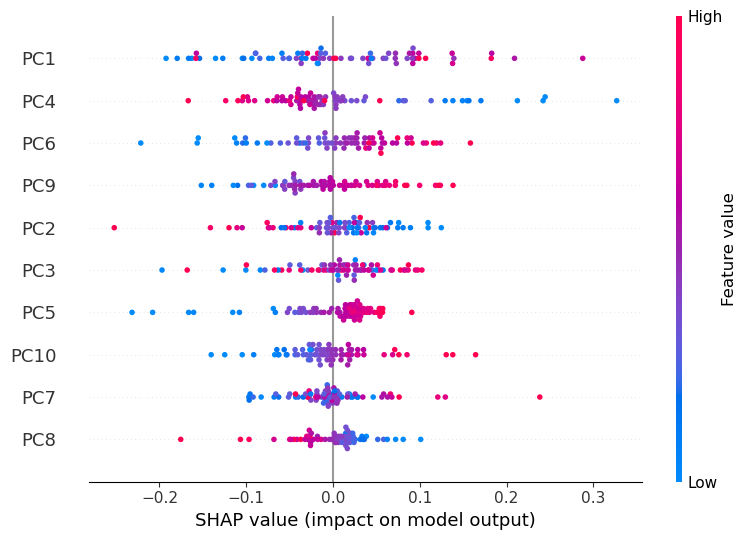

In [54]:
shap.summary_plot(shap_values, X_pca, feature_names=[f"PC{i+1}" for i in range(loadings.shape[1])],  show=False)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.savefig("Final_shap_summary.pdf")


In [55]:
if shap_values.ndim == 3:
    shap_vals = shap_values[1]   # class 1 SHAP (the usual target)
else:
    shap_vals = shap_values
shap_abs = np.abs(shap_vals).mean(axis=0)
top_indices = np.argsort(shap_abs)[::-1] + 1
print("top 3 PCs:", top_indices[:3])

top 3 PCs: [1 4 6]


In [56]:
loadings_df = pd.DataFrame(
    loadings,
    index=X_power.columns,                            # feature names
    columns=[f"PC{i+1}" for i in range(loadings.shape[1])]
)

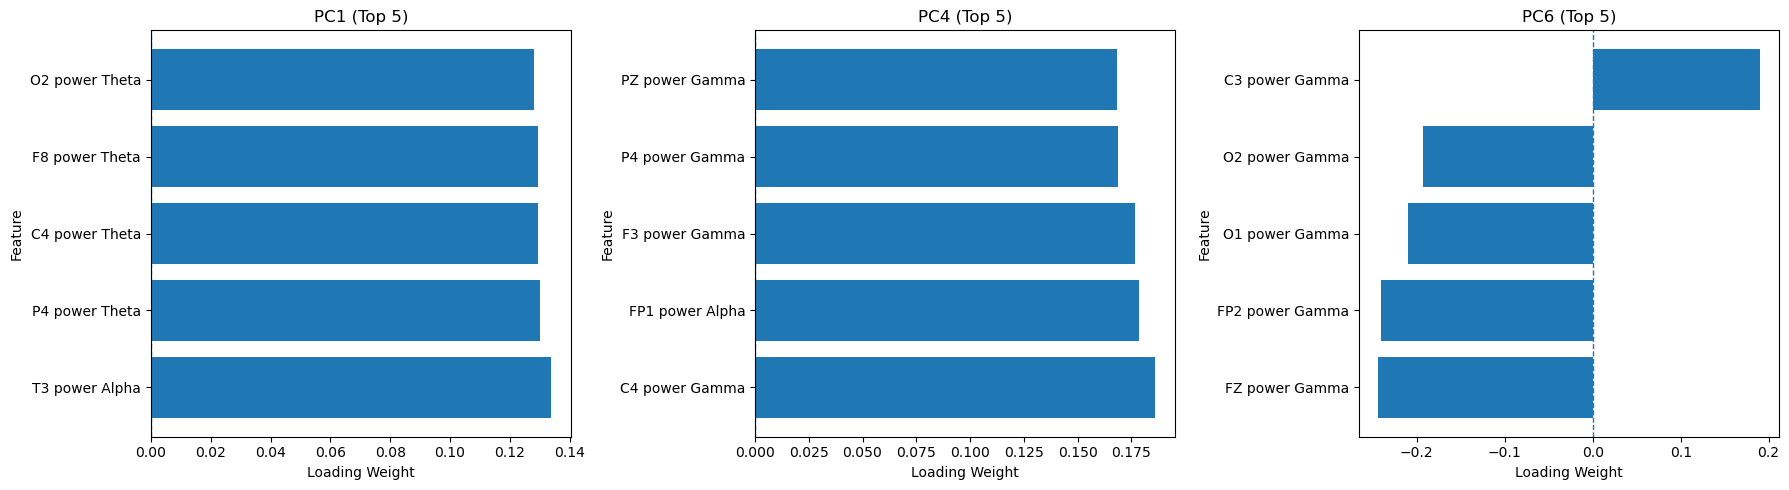

In [57]:
plot_top_loadings(loadings_df, top_pcs=top_indices[:3], save_path="Final_TopPCsLdg.pdf",top_k=5)


In [58]:
# score, pval, perm_scores = permutation_significance_pca_svm_nested(
#     X_power, y_bdi,
#     n_perm=1000,
#     outer_splits=5,
#     scoring="roc_auc"
# )

### ALl the permutation tests been ran on a SLURM cluster

#### DCA and ROC-AUC Plots 

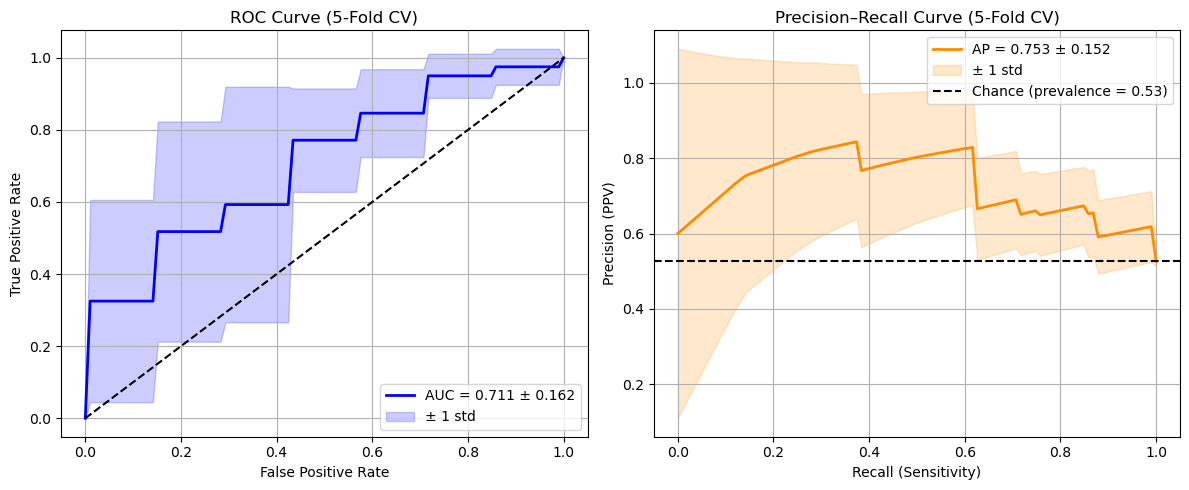

In [59]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mean_fpr = np.linspace(0, 1, 100)
tprs, roc_aucs = [], []
precisions, pr_aucs = [], []
auprs = []
mean_recall = np.linspace(0, 1, 100)
for train_idx, test_idx in outer_cv.split(X_power, y_bdi):
    X_train, X_test = X_power.iloc[train_idx], X_power.iloc[test_idx]
    y_train, y_test = y_bdi[train_idx], y_bdi[test_idx]
    grid.fit(X_train, y_train)
    y_prob = grid.predict_proba(X_test)[:, 1]
    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(auc(fpr, tpr))
    # PR
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    aupr = auc(recall, precision)
    auprs.append(aupr)
    precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))
    pr_aucs.append(average_precision_score(y_test, y_prob))
# --- Mean curves ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_roc_auc = np.mean(roc_aucs)
std_roc_auc = np.std(roc_aucs)
mean_precision = np.mean(precisions, axis=0)
mean_pr_auc = np.mean(pr_aucs)
mean_aupr = np.mean(auprs)
std_aupr = np.std(auprs)
std_pr_auc = np.std(pr_aucs)
prevalence = np.mean(y_bdi)
# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# ROC
axes[0].plot(mean_fpr, mean_tpr, color='blue', lw=2,
             label=f'AUC = {mean_roc_auc:.3f} ± {std_roc_auc:.3f}')
axes[0].fill_between(mean_fpr,
                     mean_tpr - np.std(tprs, axis=0),
                     mean_tpr + np.std(tprs, axis=0),
                     alpha=0.2, color='blue', label='± 1 std')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (5-Fold CV)')
axes[0].legend(loc='lower right')
axes[0].grid(True)
# PR
axes[1].plot(mean_recall, mean_precision, color='darkorange', lw=2,
             label=f'AP = {mean_pr_auc:.3f} ± {std_pr_auc:.3f}')
axes[1].fill_between(mean_recall,
                     mean_precision - np.std(precisions, axis=0),
                     mean_precision + np.std(precisions, axis=0),
                     alpha=0.2, color='darkorange', label='± 1 std')
axes[1].axhline(y=prevalence, color='k', linestyle='--',
                label=f'Chance (prevalence = {prevalence:.2f})')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision–Recall Curve (5-Fold CV)')
axes[1].legend(loc='upper right')
axes[1].grid(True)
plt.tight_layout()
plt.savefig('Final_ROC_PRC_5fold.pdf')
plt.show()

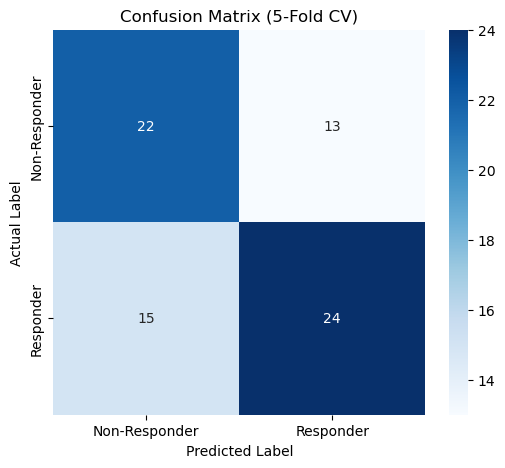

TN=22, FP=13, FN=15, TP=24


In [60]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_pred_all = np.zeros(len(y_bdi), dtype=int)

for train_idx, test_idx in outer_cv.split(X_power, y_bdi):
    X_train, X_test = X_power.iloc[train_idx], X_power.iloc[test_idx]
    y_train, y_test = y_bdi[train_idx], y_bdi[test_idx]

    grid.fit(X_train, y_train)
    y_pred_all[test_idx] = grid.predict(X_test)

# Confusion matrix on all out-of-fold predictions
cm = confusion_matrix(y_bdi, y_pred_all)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Responder', 'Responder'],
            yticklabels=['Non-Responder', 'Responder'])
plt.title('Confusion Matrix (5-Fold CV)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.savefig('Final_ConfuseMtrx.pdf')
plt.show()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

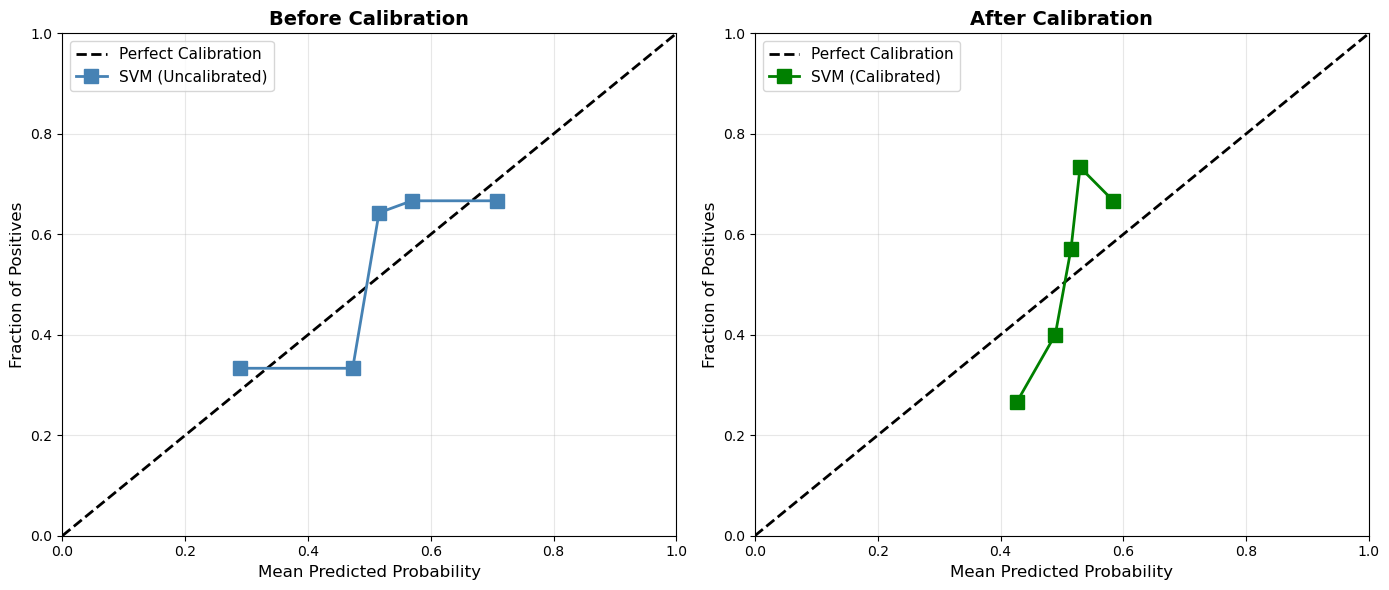

In [61]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_proba_uncal = np.zeros(len(y_bdi))
y_proba_cal = np.zeros(len(y_bdi))

for train_idx, test_idx in outer_cv.split(X_power, y_bdi):
    X_train, X_test = X_power.iloc[train_idx], X_power.iloc[test_idx]
    y_train, y_test = y_bdi[train_idx], y_bdi[test_idx]

    # --- Uncalibrated ---
    grid.fit(X_train, y_train)
    y_proba_uncal[test_idx] = grid.predict_proba(X_test)[:, 1]

    # --- Calibrated ---
    # Calibration is fitted only on X_train, tested on X_test
    calibrated_model = CalibratedClassifierCV(grid, method='sigmoid', cv=3)
    calibrated_model.fit(X_train, y_train)
    y_proba_cal[test_idx] = calibrated_model.predict_proba(X_test)[:, 1]

# --- Compare Calibration ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Uncalibrated
prob_true_uncal, prob_pred_uncal = calibration_curve(
    y_bdi, y_proba_uncal, n_bins=5, strategy='quantile'
)
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
axes[0].plot(prob_pred_uncal, prob_true_uncal, 's-', linewidth=2,
             markersize=10, color='steelblue', label='SVM (Uncalibrated)')
axes[0].set_xlabel('Mean Predicted Probability', fontsize=12)
axes[0].set_ylabel('Fraction of Positives', fontsize=12)
axes[0].set_title('Before Calibration', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1])

# Calibrated
prob_true_cal, prob_pred_cal = calibration_curve(
    y_bdi, y_proba_cal, n_bins=5, strategy='quantile'
)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
axes[1].plot(prob_pred_cal, prob_true_cal, 's-', linewidth=2,
             markersize=10, color='green', label='SVM (Calibrated)')
axes[1].set_xlabel('Mean Predicted Probability', fontsize=12)
axes[1].set_ylabel('Fraction of Positives', fontsize=12)
axes[1].set_title('After Calibration', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.savefig('Final_Calibration_5fold.pdf')
plt.show()

In [62]:
def hosmer_lemeshow(y_true, y_prob, g=10):
    """
    Hosmer-Lemeshow test for binary outcomes.
    g = number of groups (typically 10)
    """
    data = pd.DataFrame({'y': y_true, 'p': y_prob})
    data['group'] = pd.qcut(data['p'], q=g, duplicates='drop')

    obs = data.groupby('group')['y'].sum()
    exp = data.groupby('group')['p'].sum()
    n = data.groupby('group')['y'].count()

    hl_stat = np.sum((obs - exp)**2 / (exp * (1 - exp / n)))
    df = g - 2
    p_value = 1 - chi2.cdf(hl_stat, df)

    return hl_stat, p_value


In [63]:
hl_uncal, p_uncal = hosmer_lemeshow(y_bdi, y_proba_uncal)
hl_cal, p_cal = hosmer_lemeshow(y_bdi, y_proba_cal)

print("\n=== Hosmer–Lemeshow Test ===")
print(f"Uncalibrated: HL χ² = {hl_uncal:.2f}, p = {p_uncal:.4f}")
print(f"Calibrated:   HL χ² = {hl_cal:.2f}, p = {p_cal:.4f}")



=== Hosmer–Lemeshow Test ===
Uncalibrated: HL χ² = 8.99, p = 0.3435
Calibrated:   HL χ² = 7.29, p = 0.5059


In [64]:
thresh_uncal, nb_uncal, nb_all = decision_curve_analysis(y_bdi, y_proba_uncal)
thresh_cal, nb_cal, _ = decision_curve_analysis(y_bdi, y_proba_cal)

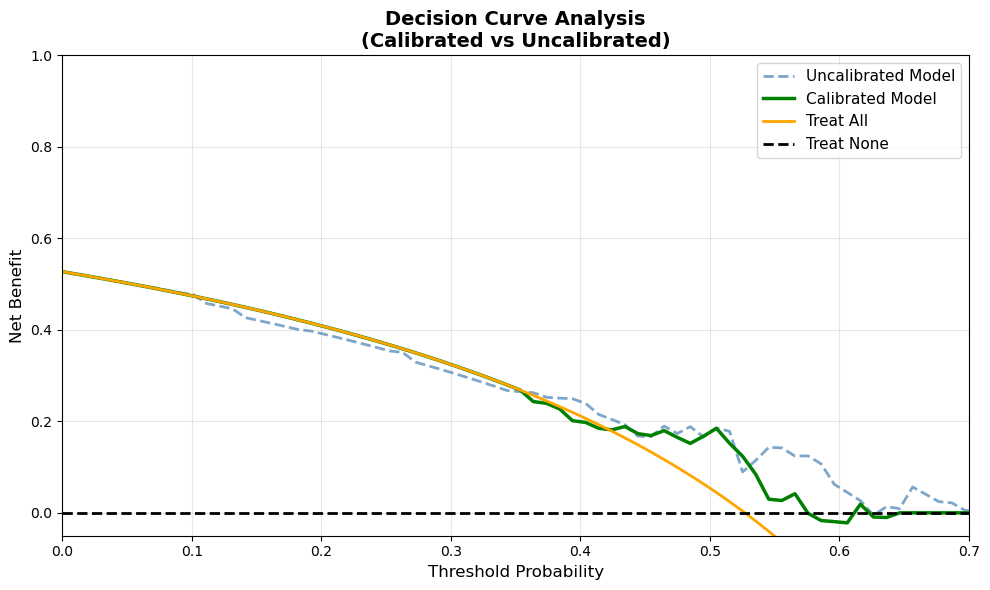

In [65]:
plt.figure(figsize=(10, 6))
plt.plot(thresh_uncal, nb_uncal, linewidth=2, color='steelblue', 
         label='Uncalibrated Model', linestyle='--', alpha=0.7)
plt.plot(thresh_cal, nb_cal, linewidth=2.5, color='green', 
         label='Calibrated Model')
plt.plot(thresh_cal, nb_all, linewidth=2, color='orange', 
         label='Treat All')
plt.axhline(y=0, color='black', linestyle='--', linewidth=2, 
            label='Treat None')

plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.xlabel('Threshold Probability', fontsize=12)
plt.ylabel('Net Benefit', fontsize=12)
plt.title('Decision Curve Analysis\n(Calibrated vs Uncalibrated)', 
          fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()


In [66]:
dca_df = decision_curve(y_bdi, y_proba_cal, thresholds=np.linspace(0.01, 0.99, 100))

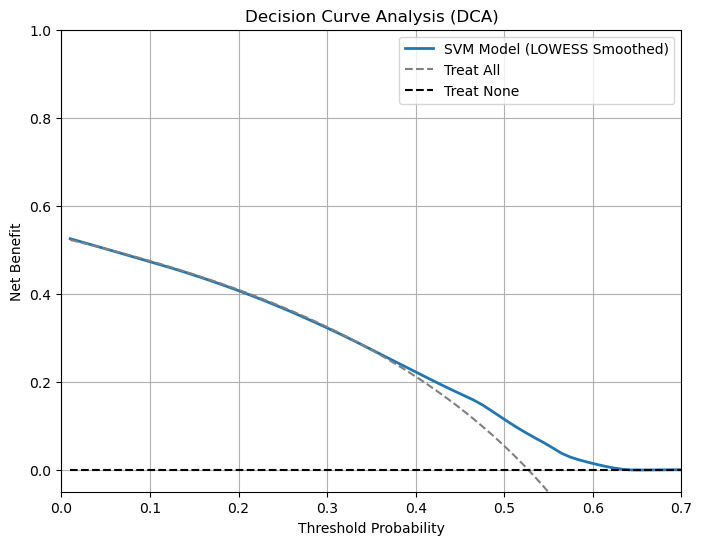

In [67]:
dca_x = dca_df["Threshold"].values
dca_y = dca_df["NetBenefit_Model"].values

# frac controls smoothing: 0.1 = modest smoothing, 0.3 = strong smoothing
smoothed = lowess(dca_y, dca_x, frac=0.25)

x_smooth = smoothed[:, 0]
y_smooth = smoothed[:, 1]

plt.figure(figsize=(8, 6))

plt.plot(x_smooth, y_smooth, label='SVM Model (LOWESS Smoothed)', lw=2)

plt.plot(dca_df['Threshold'], dca_df['NetBenefit_All'], linestyle='--', color='gray', label='Treat All')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_None'], linestyle='--', color='black', label='Treat None')

plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis (DCA)')
plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.legend()
plt.grid(True)
plt.savefig('Final_SmoothedDCA.pdf')
plt.show()

In [68]:
# Boolean arrays indicating where the model is superior
better_than_all = x_smooth > dca_df['NetBenefit_All']
better_than_none = x_smooth > dca_df['NetBenefit_None']

model_best = np.where(better_than_all & better_than_none)[0]

# Extract the threshold values
best_thresholds = dca_df['Threshold'][model_best]

print("Thresholds where model is superior:", best_thresholds.iloc[0], "to", best_thresholds.iloc[-1])


Thresholds where model is superior: 0.31686868686868686 to 0.99


In [ ]:
# threshold of interest
thr = 0.45

# Find the row closest to threshold = 0.4
idx = (dca_df['Threshold'] - thr).abs().idxmin()

# Values at that threshold
model_nb = y_smooth[idx]
treat_all_nb = dca_df.loc[idx, 'NetBenefit_All']

# Difference in net benefit
diff = model_nb - treat_all_nb

print(f"Closest threshold: {dca_df.loc[idx, 'Threshold']:.3f}")
print(f"Model net benefit: {model_nb:.4f}")
print(f"Treat-all net benefit: {treat_all_nb:.4f}")
print(f"Difference (Model - Treat All): {diff:.4f}")

## Demographics + EEG Power Data

In [70]:
Blossom_Filtered = Blossom[Blossom['id'].isin(Rest_Blossom['id'])]

In [71]:
Blossom_Filtered = Blossom_Filtered.dropna(axis=1, how='any')

In [72]:
eeg_features_start_index = Blossom_Filtered.columns.get_loc('A2_A1_Delta_Coherence')

In [73]:
Blossom_demographic = Blossom_Filtered.iloc[:,:eeg_features_start_index-4]

In [74]:
Blossom_demographic['tms_1_1_stimulation_site_1_Bi_DLPFC'] = Blossom_demographic['tms_1_1_stimulation_site_1_Rt_DLPFC'] - Blossom_demographic['tms_1_1_stimulation_site_1_Lt_DLPFC']

In [75]:
Blossom_demographic = Blossom_demographic.drop(['tms_1_1_stimulation_site_1_Lt_DLPFC', 'tms_1_1_stimulation_site_1_Rt_DLPFC', 'cgi_1_to_12_midpoint_change',
       'bdi_1_12_midpoint_change', 'bdi_1_to_12_total_change',
       'bdi_responder', 'bdi_remitter', 'bai_1_to_12_midpoint_change',
       'bai_1_to_12_total_change', 'bdi_1_12_bdi', 'bdi_2_12_bdi', 'bai_1_12_bai', 'bai_2_12_bai','cgi_s_1_12_cgi', 'cgi_i_1_12_cgi'], axis=1)

In [76]:
X_demo = Blossom_demographic.iloc[:,1:]

In [77]:
X = Rest_Blossom.iloc[:,1:-1]

In [78]:
merged_df = pd.merge(Blossom_demographic, Rest_Blossom.iloc[:,:-1], on='id', how='outer')

In [79]:
merged_df = merged_df.iloc[:,1:]

In [80]:
# Find constant columns
constant_cols = [col for col in X_demo.columns if X_demo[col].nunique() == 1]
print("Constant columns:", constant_cols)

X_demo = X_demo.drop(columns=constant_cols)

Constant columns: ['tms_1_1_pulse_site_2_1500']


In [81]:
X_demo_refined = Blossom_demographic.loc[:,['age','bdi_1_1_bdi','bai_1_1_bai','msm','cgi_s_1_1_cgi','gender_M']] # Dropping all the TMS variables

#### Only using Demo Data, Features selections

In [82]:
X_demo_refined = X_demo_refined.reset_index(drop=True)

In [83]:
# ============================================
# Custom SelectKBest that caps k dynamically
# ============================================
class SafeSelectKBest(BaseEstimator, TransformerMixin):
    def __init__(self, score_func=f_classif, k=10):
        self.score_func = score_func
        self.k = k
    def fit(self, X, y=None):
        k = min(self.k, X.shape[1])
        self.selector_ = SelectKBest(score_func=self.score_func, k=k)
        self.selector_.fit(X, y)
        return self
    def transform(self, X):
        return self.selector_.transform(X)
    def get_support(self):
        return self.selector_.get_support()

# ============================================
# Build a pipeline for any classifier
# ============================================
def make_pipeline(clf):
    return Pipeline([
        ('var_thresh', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('select', SafeSelectKBest(score_func=f_classif)),
        ('clf', clf)
    ])

k_range = list(range(1, len(X_demo_refined.columns) + 1))

# ============================================
# Model configurations
# ============================================
models_demo = {
    'SVM': {
        'pipeline': make_pipeline(SVC(kernel='rbf', probability=True, random_state=42)),
        'param_grid': {
            'select__k': k_range,
            'clf__C': [10, 20, 50, 100, 300, 500, 1000],
            'clf__gamma': [0.001, 0.005, 0.01, 0.05, 0.1],
        }
    },
    'LogisticRegression': {
        'pipeline': make_pipeline(
            LogisticRegression(solver='liblinear', max_iter=5000, random_state=42)
        ),
        'param_grid': {
            'select__k': k_range,
            'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'clf__penalty': ['l1', 'l2'],
        }
    },
    'RandomForest': {
        'pipeline': make_pipeline(RandomForestClassifier(random_state=42, n_jobs=1)),
        'param_grid': {
            'select__k': k_range,
            'clf__n_estimators': [300],           # one value is fine
            'clf__max_depth': [None, 10],         # 2 instead of 4
            'clf__min_samples_split': [2, 5],     # 2 instead of 3
            'clf__max_features': ['sqrt'],        # 1 instead of 2
        }
    },
}

# ============================================
# CV setup + scoring
# ============================================
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'specificity': make_scorer(recall_score, pos_label=0)
}

# ============================================
# Nested CV across all models
# ============================================
all_results = {}

for name, cfg in models_demo.items():
    print(f"\n>>> Running nested CV for {name}...")
    grid = GridSearchCV(
        cfg['pipeline'],
        cfg['param_grid'],
        scoring='roc_auc',
        cv=inner_cv,
        n_jobs=-1
    )
    results = cross_validate(
        grid,
        X_demo_refined,
        y_bdi,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )
    all_results[name] = results

# ============================================
# Summary table
# ============================================
print("\n=== Nested Cross-Validation Results (Demo) ===\n")
summary_rows = []
for name, results in all_results.items():
    row = {'model': name}
    for metric in scoring.keys():
        scores = results[f'test_{metric}']
        row[metric] = f"{scores.mean():.3f} ± {scores.std():.3f}"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('model')
print(summary_df.to_string())


>>> Running nested CV for SVM...

>>> Running nested CV for LogisticRegression...

>>> Running nested CV for RandomForest...

=== Nested Cross-Validation Results (Demo) ===

                          roc_auc average_precision balanced_accuracy      precision         recall             f1    specificity
model                                                                                                                            
SVM                 0.692 ± 0.066     0.736 ± 0.044     0.688 ± 0.075  0.724 ± 0.100  0.718 ± 0.145  0.704 ± 0.069  0.657 ± 0.214
LogisticRegression  0.566 ± 0.044     0.626 ± 0.062     0.561 ± 0.051  0.586 ± 0.058  0.664 ± 0.248  0.591 ± 0.135  0.457 ± 0.210
RandomForest        0.651 ± 0.041     0.711 ± 0.081     0.643 ± 0.070  0.668 ± 0.096  0.743 ± 0.113  0.691 ± 0.033  0.543 ± 0.229


In [84]:
# -----------------------------------------------------------------
# Pick the best model TYPE from the nested-CV results
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'          # match what GridSearchCV optimised
 
mean_scores = {name: res[f'test_{SELECTION_METRIC}'].mean()
               for name, res in all_results.items()}
best_name = max(mean_scores, key=mean_scores.get)
print(f"Best model by mean {SELECTION_METRIC}: "
      f"{best_name} ({mean_scores[best_name]:.3f})")
 
# -----------------------------------------------------------------
# Refit ONE final model on all the data.
# -----------------------------------------------------------------
best_cfg = models_demo[best_name]
final_grid = GridSearchCV(
    best_cfg['pipeline'],
    best_cfg['param_grid'],
    scoring=SELECTION_METRIC,
    cv=inner_cv,
    n_jobs=-1,
)
final_grid.fit(X_demo_refined, y_bdi)
final_pipe = final_grid.best_estimator_
print("Best hyper-parameters:", final_grid.best_params_)

Best model by mean roc_auc: SVM (0.692)
Best hyper-parameters: {'clf__C': 100, 'clf__gamma': 0.005, 'select__k': 6}


In [85]:
final_grid.fit(X_demo_refined, y_bdi)
final_pipe = final_grid.best_estimator_
print("Best hyper-parameters:", final_grid.best_params_)

Best hyper-parameters: {'clf__C': 100, 'clf__gamma': 0.005, 'select__k': 6}


In [86]:
# -----------------------------------------------------------------
# Recover the feature matrix that actually reaches the classifier,
#    plus its column names (PCs + demo features) — same logic as the
#    feature-frequency loop, applied to this single model.
# -----------------------------------------------------------------
final_feature_names = X_demo_refined.columns.values
 
# everything except the classifier == the transformed input to clf
X_clf = pd.DataFrame(final_pipe[:-1].transform(X_demo_refined),
                     columns=final_feature_names)
clf = final_pipe.named_steps['clf']
 

In [87]:
# SHAP — pick an explainer that matches the model family
# -----------------------------------------------------------------
if best_name == 'RandomForest':
    explainer   = shap.TreeExplainer(clf)
    explanation = explainer(X_clf, check_additivity=False)
    if explanation.values.ndim == 3:          # (n, feats, classes)
        explanation = explanation[..., 1]     # positive class
 
elif best_name == 'LogisticRegression':
    explainer   = shap.LinearExplainer(clf, X_clf)
    explanation = explainer(X_clf)
 
else:  # SVM (rbf) — no exact explainer; KernelExplainer on P(positive)
    bg = X_clf.sample(min(50, len(X_clf)), random_state=42)
    explainer = shap.KernelExplainer(
        lambda d: clf.predict_proba(d)[:, 1], bg.values
    )
    sv = explainer.shap_values(X_clf.values, nsamples=200)  # slow-ish
    explanation = shap.Explanation(
        values=sv,
        base_values=explainer.expected_value,
        data=X_clf.values,
        feature_names=list(final_feature_names),
    )
 

  0%|          | 0/74 [00:00<?, ?it/s]

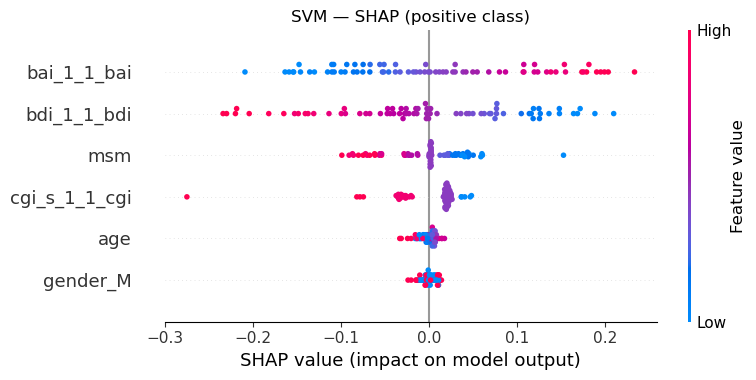

In [88]:
# -----------------------------------------------------------------
# Plots
# -----------------------------------------------------------------
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title(f"{best_name} — SHAP (positive class)")
plt.tight_layout(); plt.savefig('Final_baseline_shap_beeswarm.pdf', dpi=150); plt.show()

Generating CV curves + confusion matrix for: SVM


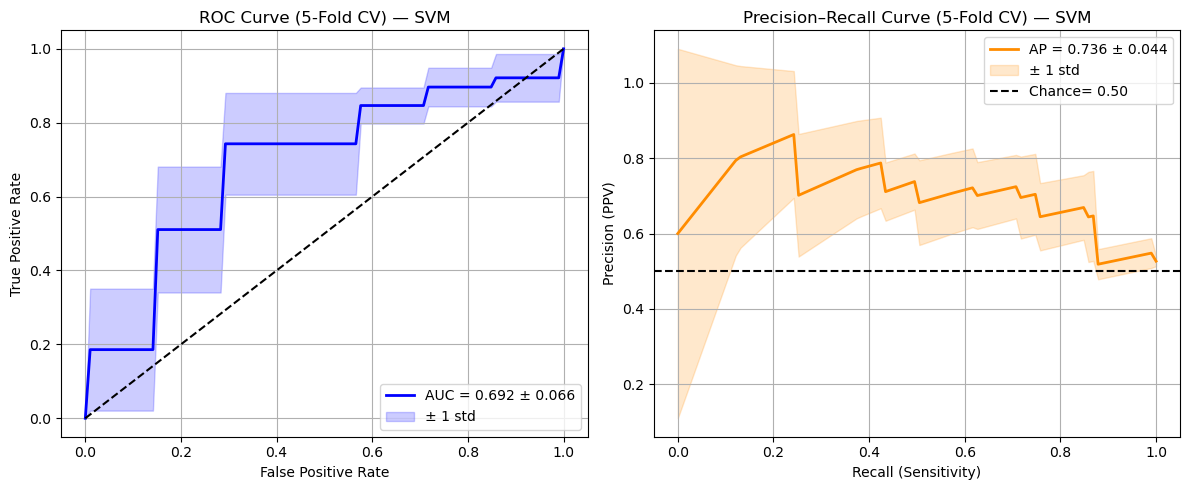

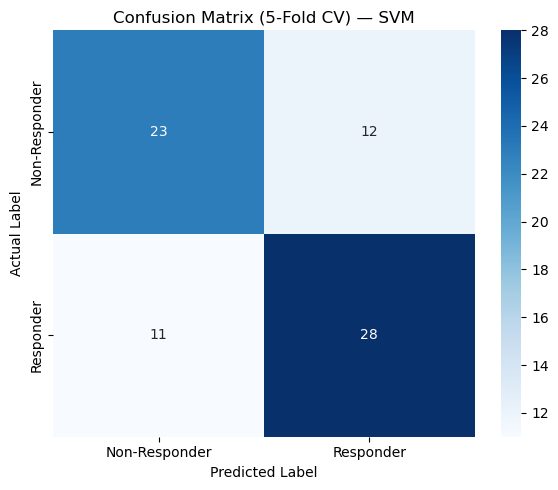

TN=23, FP=12, FN=11, TP=28


In [89]:
# ============================================
# Out-of-fold ROC / PR curves + confusion matrix
# for the best cross-validated model.
# ============================================
# -----------------------------------------------------------------
# Best model type (same selection as the SHAP script)
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'
best_name = 'SVM'
best_cfg = models_demo[best_name]
print(f"Generating CV curves + confusion matrix for: {best_name}")

grid = GridSearchCV(best_cfg['pipeline'], best_cfg['param_grid'],
                    scoring=SELECTION_METRIC, cv=inner_cv, n_jobs=-1)

# -----------------------------------------------------------------
# Single nested-CV loop: collect ROC, PR, and out-of-fold predictions
# (one grid.fit per fold instead of two => half the compute, and the
#  curves and confusion matrix come from the exact same fits)
# -----------------------------------------------------------------
y_arr = np.asarray(y_bdi)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mean_fpr = np.linspace(0, 1, 100)
tprs, roc_aucs = [], []
precisions, pr_aucs = [], []
mean_recall = np.linspace(0, 1, 100)
y_pred_all = np.zeros(len(y_arr), dtype=int)

for train_idx, test_idx in outer_cv.split(X_demo_refined, y_arr):
    X_train, X_test = X_demo_refined.iloc[train_idx], X_demo_refined.iloc[test_idx]
    y_train, y_test = y_arr[train_idx], y_arr[test_idx]

    grid.fit(X_train, y_train)                       # inner hyper-search, per fold
    # print(grid.best_estimator_.classes_)
    y_prob = grid.decision_function(X_test)
    y_pred_all[test_idx] = grid.predict(X_test)

    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(auc(fpr, tpr))

    # PR  (reverse so recall is increasing for np.interp)
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))
    pr_aucs.append(average_precision_score(y_test, y_prob))

# --- Mean curves ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_roc_auc = np.mean(roc_aucs)
std_roc_auc = np.std(roc_aucs)
mean_precision = np.mean(precisions, axis=0)
mean_pr_auc = np.mean(pr_aucs)
std_pr_auc = np.std(pr_aucs)


# -----------------------------------------------------------------
# Figure 1: ROC + PR
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(mean_fpr, mean_tpr, color='blue', lw=2,
             label=f'AUC = {mean_roc_auc:.3f} ± {std_roc_auc:.3f}')
axes[0].fill_between(mean_fpr,
                     mean_tpr - np.std(tprs, axis=0),
                     mean_tpr + np.std(tprs, axis=0),
                     alpha=0.2, color='blue', label='± 1 std')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title(f'ROC Curve (5-Fold CV) — {best_name}')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# PR
axes[1].plot(mean_recall, mean_precision, color='darkorange', lw=2,
             label=f'AP = {mean_pr_auc:.3f} ± {std_pr_auc:.3f}')
axes[1].fill_between(mean_recall,
                     mean_precision - np.std(precisions, axis=0),
                     mean_precision + np.std(precisions, axis=0),
                     alpha=0.2, color='darkorange', label='± 1 std')
axes[1].axhline(y=0.5, color='k', linestyle='--',
                label=f'Chance= {0.5:.2f}')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title(f'Precision–Recall Curve (5-Fold CV) — {best_name}')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('Final_baseline_ROC_PRC_5fold.pdf')
plt.show()

# -----------------------------------------------------------------
# Figure 2: confusion matrix on all out-of-fold predictions
# -----------------------------------------------------------------
cm = confusion_matrix(y_arr, y_pred_all)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Responder', 'Responder'],
            yticklabels=['Non-Responder', 'Responder'])
plt.title(f'Confusion Matrix (5-Fold CV) — {best_name}')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('Final_baseline_ConfuseMtrx.pdf')
plt.show()

print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Calibration + DCA for: SVM
Best hyper-parameters: {'clf__C': 100, 'clf__gamma': 0.005, 'select__k': 6}


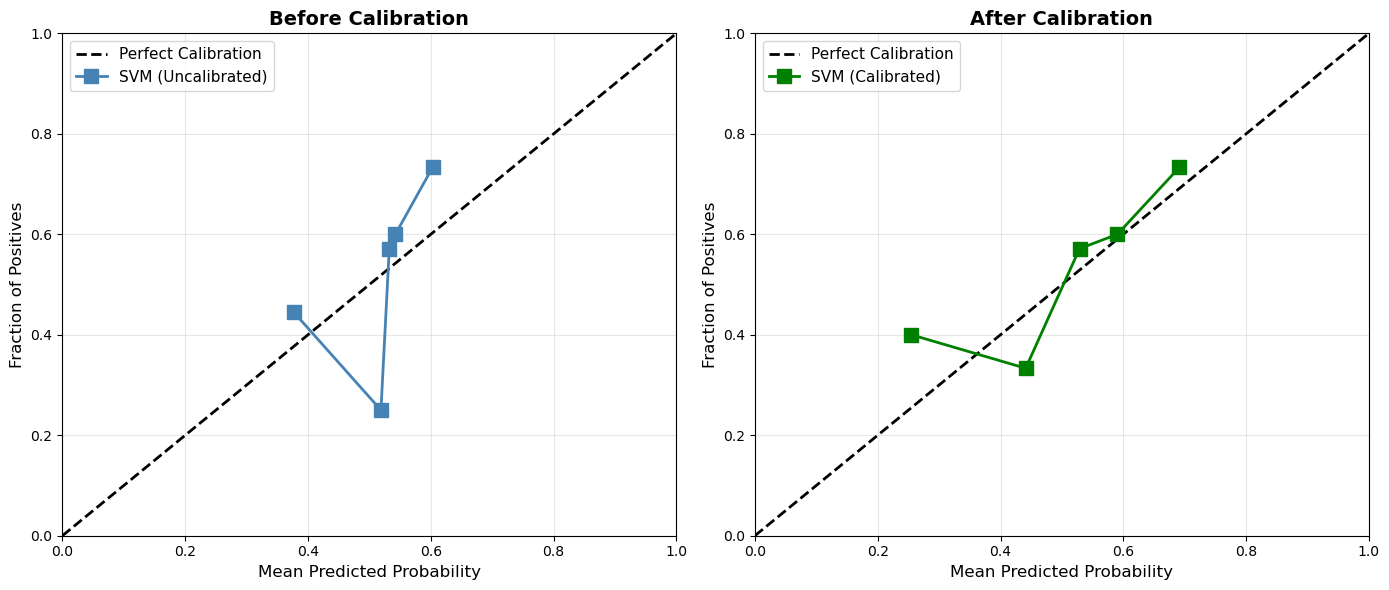


=== Hosmer-Lemeshow Test ===
Uncalibrated: HL chi2 = 10.59, p = 0.2259 (df=8)
Calibrated:   HL chi2 = 7.05, p = 0.5313 (df=8)
(higher p = better fit; p>0.05 => no significant miscalibration)


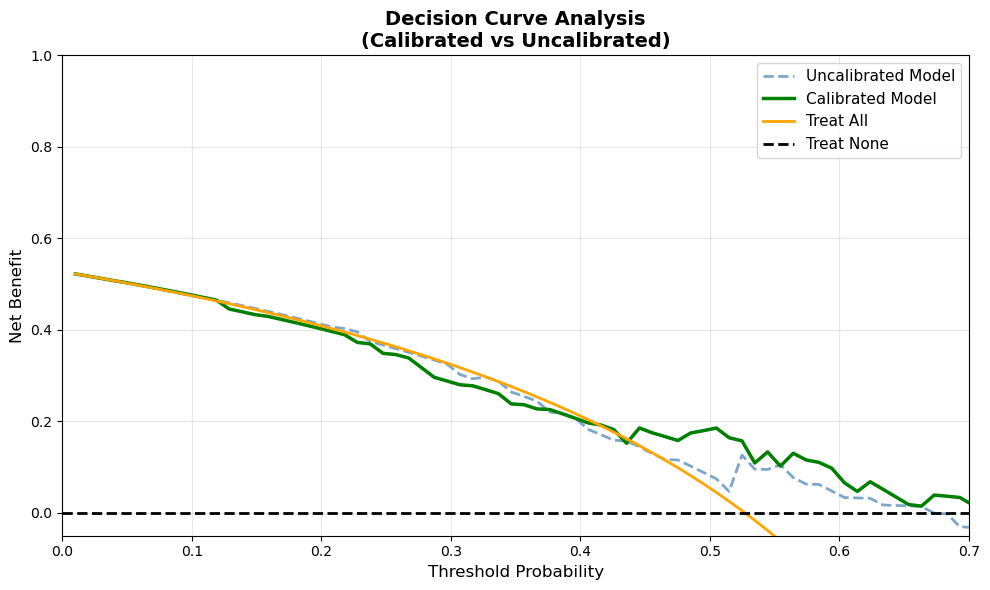

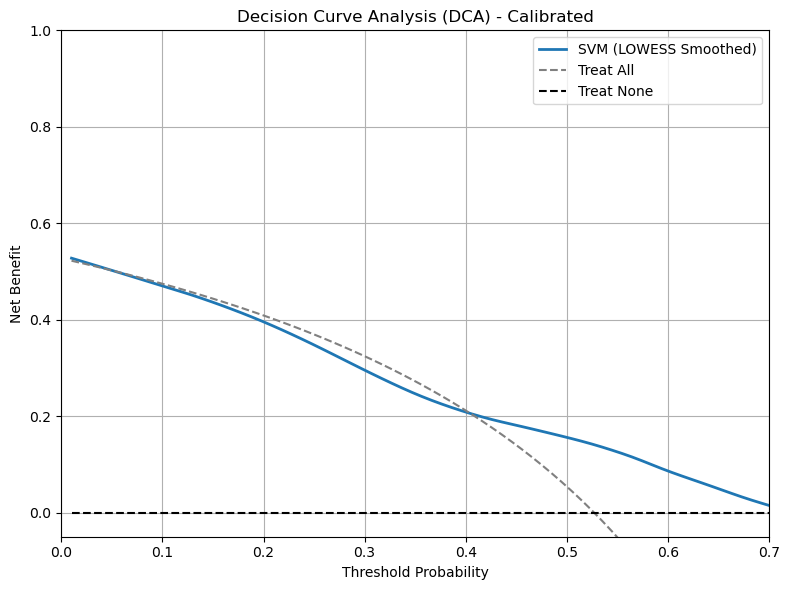


Model beats both references between threshold 0.010 and 0.772 (non-contiguous).

Closest threshold: 0.446
Model net benefit:     0.1832
Treat-all net benefit: 0.1469
Difference (Model - Treat All): 0.0363


In [90]:
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    _HAS_LOWESS = True
except Exception:
    _HAS_LOWESS = False

# -----------------------------------------------------------------
# Best model (same selection as the SHAP / curves scripts)
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'
best_name = 'SVM'
best_cfg = models_demo[best_name]
print(f"Calibration + DCA for: {best_name}")


final_grid = GridSearchCV(best_cfg['pipeline'], best_cfg['param_grid'],
                          scoring=SELECTION_METRIC, cv=inner_cv, n_jobs=-1)
final_grid.fit(X_demo_refined, y_bdi)
best_pipe = final_grid.best_estimator_
print("Best hyper-parameters:", final_grid.best_params_)

# -----------------------------------------------------------------
# Out-of-fold probabilities: uncalibrated vs sigmoid-calibrated
# -----------------------------------------------------------------
y_arr = np.asarray(y_bdi)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_proba_uncal = np.zeros(len(y_arr))
y_proba_cal = np.zeros(len(y_arr))

for train_idx, test_idx in outer_cv.split(X_demo_refined, y_arr):
    X_train, X_test = X_demo_refined.iloc[train_idx], X_demo_refined.iloc[test_idx]
    y_train = y_arr[train_idx]

    # Uncalibrated
    uncal = clone(best_pipe).fit(X_train, y_train)
    y_proba_uncal[test_idx] = uncal.predict_proba(X_test)[:, 1]

    # Calibrated (calibration fit only on the training fold)
    cal = CalibratedClassifierCV(clone(best_pipe), method='sigmoid', cv=3)
    cal.fit(X_train, y_train)
    y_proba_cal[test_idx] = cal.predict_proba(X_test)[:, 1]

# -----------------------------------------------------------------
# Calibration curves: before vs after
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, proba, color, label, title in [
    (axes[0], y_proba_uncal, 'steelblue', f'{best_name} (Uncalibrated)', 'Before Calibration'),
    (axes[1], y_proba_cal,   'green',     f'{best_name} (Calibrated)',   'After Calibration'),
]:
    prob_true, prob_pred = calibration_curve(y_arr, proba, n_bins=5, strategy='quantile')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
    ax.plot(prob_pred, prob_true, 's-', linewidth=2, markersize=10, color=color, label=label)
    ax.set_xlabel('Mean Predicted Probability', fontsize=12)
    ax.set_ylabel('Fraction of Positives', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig('Final_baseline_Calibration_5fold.pdf')
plt.show()

# -----------------------------------------------------------------
# Hosmer-Lemeshow goodness-of-fit
# -----------------------------------------------------------------
def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': np.asarray(y_true), 'p': np.asarray(y_prob)})
    data['group'] = pd.qcut(data['p'], q=g, duplicates='drop')
    obs = data.groupby('group', observed=True)['y'].sum()
    exp = data.groupby('group', observed=True)['p'].sum()
    n = data.groupby('group', observed=True)['y'].count()
    hl_stat = np.sum((obs - exp) ** 2 / (exp * (1 - exp / n)))
    dof = data['group'].nunique() - 2          # actual groups, not g
    if dof < 1:
        return hl_stat, np.nan, dof
    return hl_stat, 1 - chi2.cdf(hl_stat, dof), dof

hl_uncal, p_uncal, df_uncal = hosmer_lemeshow(y_arr, y_proba_uncal)
hl_cal, p_cal, df_cal = hosmer_lemeshow(y_arr, y_proba_cal)
print("\n=== Hosmer-Lemeshow Test ===")
print(f"Uncalibrated: HL chi2 = {hl_uncal:.2f}, p = {p_uncal:.4f} (df={df_uncal})")
print(f"Calibrated:   HL chi2 = {hl_cal:.2f}, p = {p_cal:.4f} (df={df_cal})")
print("(higher p = better fit; p>0.05 => no significant miscalibration)")

# -----------------------------------------------------------------
# Decision Curve Analysis (net benefit, Vickers & Elkin)
# -----------------------------------------------------------------
def decision_curve(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    n = len(y_true); prev = y_true.mean()
    rows = []
    for pt in thresholds:
        pred_pos = y_prob >= pt
        tp = np.sum(pred_pos & (y_true == 1))
        fp = np.sum(pred_pos & (y_true == 0))
        w = pt / (1 - pt)
        nb_model = tp / n - (fp / n) * w
        nb_all = prev - (1 - prev) * w
        rows.append((pt, nb_model, nb_all, 0.0))
    return pd.DataFrame(rows, columns=['Threshold', 'NetBenefit_Model',
                                       'NetBenefit_All', 'NetBenefit_None'])

thr_grid = np.linspace(0.01, 0.99, 100)
dca_uncal = decision_curve(y_arr, y_proba_uncal, thr_grid)
dca_cal = decision_curve(y_arr, y_proba_cal, thr_grid)

# --- Calibrated vs uncalibrated, with reference strategies ---
plt.figure(figsize=(10, 6))
plt.plot(dca_uncal['Threshold'], dca_uncal['NetBenefit_Model'], '--',
         color='steelblue', lw=2, alpha=0.7, label='Uncalibrated Model')
plt.plot(dca_cal['Threshold'], dca_cal['NetBenefit_Model'],
         color='green', lw=2.5, label='Calibrated Model')
plt.plot(dca_cal['Threshold'], dca_cal['NetBenefit_All'],
         color='orange', lw=2, label='Treat All')
plt.axhline(y=0, color='black', linestyle='--', lw=2, label='Treat None')
plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.xlabel('Threshold Probability', fontsize=12)
plt.ylabel('Net Benefit', fontsize=12)
plt.title('Decision Curve Analysis\n(Calibrated vs Uncalibrated)',
          fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('DCA_cal_vs_uncal.pdf')
plt.show()

# --- LOWESS-smoothed calibrated curve ---
dca_df = dca_cal
dca_x = dca_df['Threshold'].values
dca_y = dca_df['NetBenefit_Model'].values

if _HAS_LOWESS:
    smoothed = lowess(dca_y, dca_x, frac=0.25)   # frac: 0.1 light .. 0.3 strong
    x_smooth, y_smooth = smoothed[:, 0], smoothed[:, 1]
else:
    x_smooth, y_smooth = dca_x, dca_y
    print("statsmodels not installed -> showing raw calibrated DCA "
          "(pip install statsmodels for LOWESS smoothing).")

plt.figure(figsize=(8, 6))
plt.plot(x_smooth, y_smooth, lw=2,
         label=f'{best_name} ({"LOWESS Smoothed" if _HAS_LOWESS else "raw"})')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_All'], '--', color='gray', label='Treat All')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_None'], '--', color='black', label='Treat None')
plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis (DCA) - Calibrated')
plt.xlim(0, 0.7)
plt.ylim(-0.05, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('Final_baseline_SmoothedDCA.pdf')
plt.show()

# -----------------------------------------------------------------
# Where does the model beat BOTH references? (compare net benefit, y_smooth)
# -----------------------------------------------------------------
nb_all = dca_df['NetBenefit_All'].values          # aligned with x_smooth (sorted grid)
better_than_all = y_smooth > nb_all
better_than_none = y_smooth > 0.0
superior = np.where(better_than_all & better_than_none)[0]

if superior.size:
    th = dca_df['Threshold'].values[superior]
    print(f"\nModel beats both references between threshold "
          f"{th.min():.3f} and {th.max():.3f}"
          f"{' (non-contiguous)' if np.any(np.diff(superior) > 1) else ''}.")
else:
    print("\nModel never strictly beats both references in this range.")

# --- Net benefit at a clinical threshold of interest ---
thr = 0.45
idx = int(np.argmin(np.abs(dca_df['Threshold'].values - thr)))
model_nb = y_smooth[idx]
treat_all_nb = dca_df['NetBenefit_All'].values[idx]
print(f"\nClosest threshold: {dca_df['Threshold'].values[idx]:.3f}")
print(f"Model net benefit:     {model_nb:.4f}")
print(f"Treat-all net benefit: {treat_all_nb:.4f}")
print(f"Difference (Model - Treat All): {model_nb - treat_all_nb:.4f}")

In [91]:
# obs, pvals, perm = permutation_test_svm(X_demo_refined, y_bdi, models, scoring, n_perm=1000)

In [92]:
# for metric in scoring.keys():
#     scores = results_demo_final[f'test_{metric}']
#     print(f"{metric:20s}: {scores.mean():.3f} ± {scores.std():.3f}")


In [93]:
# print_report(results_demo_final, scoring)


### EEG + DEMO

In [94]:
X_demo = X_demo.reset_index(drop=True)

X_demo_refined = X_demo_refined.reset_index(drop=True)

In [95]:
# ============================================
# SafeSelectKBest
# ============================================
class SafeSelectKBest(BaseEstimator, TransformerMixin):
    """SelectKBest that silently caps k to the number of available features."""
    def __init__(self, score_func=f_classif, k=10):
        self.score_func = score_func
        self.k = k

    def fit(self, X, y=None):
        self.selector_ = SelectKBest(
            score_func=self.score_func,
            k=min(self.k, X.shape[1])
        )
        self.selector_.fit(X, y)
        return self

    def transform(self, X):
        return self.selector_.transform(X)

    def get_support(self):
        return self.selector_.get_support()

# ============================================
# Combined dataset
# ============================================
features_demo = X_demo_refined.columns.tolist()
features_power = X_power.columns.tolist()
X_all = pd.concat([X_power, X_demo_refined], axis=1)

# ============================================
# Build a pipeline for any classifier
# ============================================
def make_pipeline(clf):
    preprocessor = ColumnTransformer(
        transformers=[
            ('power', Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(random_state=42))
            ]), features_power),
            ('demo', Pipeline([
                ('scaler', StandardScaler())
            ]), features_demo)
        ]
    )
    return Pipeline([
        ('preproc', preprocessor),
        ('var_thresh', VarianceThreshold(threshold=0.0)),
        ('select', SafeSelectKBest(score_func=f_classif)),
        ('clf', clf)
    ])

# ============================================
# Model configurations
# ============================================
# Trimmed grid used by LR and RF only (for speed).

max_pca = 30  # max of pca__n_components grid


trimmed_shared_grid = {
    'preproc__power__pca__n_components': [5, 10, 15, 20, 25, 30],
    'select__k': list(range(1, max_pca + len(features_demo) + 1)),
}

models_all = {
    'SVM': {
        'pipeline': make_pipeline(SVC(kernel='rbf', probability=True, random_state=42)),
        'param_grid': {
            'preproc__power__pca__n_components': [5, 10, 15, 20, 25, 30],
            'select__k': list(range(1, max_pca + len(features_demo) + 1)),
            'clf__C': [10, 20, 50, 100, 300, 500, 1000],
            'clf__gamma': [0.001, 0.005, 0.01, 0.05, 0.1],
        }
    },
    
    'LogisticRegression': {
        'pipeline': make_pipeline(
            LogisticRegression(solver='liblinear', max_iter=5000, random_state=42)
        ),
        'param_grid': {
            **trimmed_shared_grid,
            'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'clf__penalty': ['l1', 'l2'],
        }
    },
    'RandomForest': {
        'pipeline': make_pipeline(
            RandomForestClassifier(random_state=42, n_jobs=1)
        ),
        'param_grid': {
            **trimmed_shared_grid,
            'clf__n_estimators': [300],
            'clf__max_depth': [None, 10],
            'clf__min_samples_split': [2, 5],
            'clf__max_features': ['sqrt'],
        }
    },
}

# ============================================
# CV setup + scoring
# ============================================
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
    'balanced_accuracy': 'balanced_accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'specificity': make_scorer(recall_score, pos_label=0)
}

MAX_PCS = 30  # upper bound used to size the feature-frequency index

# ============================================
# Nested CV + feature frequency, per model
# ============================================
all_results = {}
all_feature_counts = {}

for name, cfg in models_all.items():
    print(f"\n>>> Running nested CV for {name}...")

    grid = GridSearchCV(
        cfg['pipeline'],
        cfg['param_grid'],
        scoring='roc_auc',
        cv=inner_cv,
        n_jobs=-1                       # inner: parallel
    )

    # --- Nested CV metrics + estimators in one pass ---
    results = cross_validate(
        grid, X_all, y_bdi,
        cv=outer_cv, scoring=scoring,
        n_jobs=1,                       # outer: serial
        return_train_score=False,
        return_estimator=True           # reuse fitted estimators for feature freq
    )
    all_results[name] = results

    # --- Feature selection frequency, reusing fitted estimators ---
    selected_counts = pd.Series(
        0, index=[f'PC{i+1}' for i in range(MAX_PCS)] + features_demo
    )
    for fitted_grid in results['estimator']:
        best_pipe = fitted_grid.best_estimator_

        pca_step = (best_pipe.named_steps['preproc']
                             .named_transformers_['power']
                             .named_steps['pca'])
        n_pcs = pca_step.n_components_
        pca_names = [f'PC{i+1}' for i in range(n_pcs)]

        all_feature_names = np.array(pca_names + features_demo)
        var_mask = best_pipe.named_steps['var_thresh'].get_support()
        features_after_var = all_feature_names[var_mask]
        sel_mask = best_pipe.named_steps['select'].get_support()
        selected = features_after_var[sel_mask]
        selected_counts[selected] += 1

    all_feature_counts[name] = selected_counts

# ============================================
# Summary table of metrics
# ============================================
print("\n=== Nested Cross-Validation Results (Power + Demo) ===\n")
summary_rows = []
for name, results in all_results.items():
    row = {'model': name}
    for metric in scoring.keys():
        scores = results[f'test_{metric}']
        row[metric] = f"{scores.mean():.3f} ± {scores.std():.3f}"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('model')
print(summary_df.to_string())

# ============================================
# Feature frequency per model
# ============================================
print("\n=== Feature Selection Frequency Across Folds ===")
freq_df = pd.DataFrame(all_feature_counts)
freq_df = freq_df.loc[freq_df.sum(axis=1) > 0]
freq_df = freq_df.sort_values(by=list(freq_df.columns), ascending=False)
print(freq_df.to_string())


>>> Running nested CV for SVM...

>>> Running nested CV for LogisticRegression...

>>> Running nested CV for RandomForest...

=== Nested Cross-Validation Results (Power + Demo) ===

                          roc_auc average_precision balanced_accuracy      precision         recall             f1    specificity
model                                                                                                                            
SVM                 0.755 ± 0.097     0.808 ± 0.105     0.689 ± 0.092  0.711 ± 0.091  0.693 ± 0.097  0.700 ± 0.089  0.686 ± 0.107
LogisticRegression  0.714 ± 0.146     0.773 ± 0.119     0.625 ± 0.124  0.664 ± 0.120  0.621 ± 0.130  0.635 ± 0.104  0.629 ± 0.194
RandomForest        0.679 ± 0.123     0.729 ± 0.121     0.623 ± 0.116  0.667 ± 0.174  0.618 ± 0.172  0.627 ± 0.128  0.629 ± 0.194

=== Feature Selection Frequency Across Folds ===
               SVM  LogisticRegression  RandomForest
PC4              5                   5             3
PC7        

In [96]:
# obs, pvals, perm = permutation_test_svm(X_all, y_bdi, models_all, scoring, n_perm=5)

### Bootstrapps

In [97]:
# --- metric registry: score-based (need ranking scores) vs label-based ---
_SCORE_METRICS = {
    'roc_auc':           lambda yt, s, p: roc_auc_score(yt, s),
    'average_precision': lambda yt, s, p: average_precision_score(yt, s),
}
_LABEL_METRICS = {
    'balanced_accuracy': lambda yt, s, p: balanced_accuracy_score(yt, p),
    'precision':         lambda yt, s, p: precision_score(yt, p, zero_division=0),
    'recall':            lambda yt, s, p: recall_score(yt, p, zero_division=0),
    'f1':                lambda yt, s, p: f1_score(yt, p, zero_division=0),
    'specificity':       lambda yt, s, p: recall_score(yt, p, pos_label=0, zero_division=0),
}
METRICS = {**_SCORE_METRICS, **_LABEL_METRICS}


def _take(X, idx):
    return X.iloc[idx] if hasattr(X, 'iloc') else X[idx]


def _ranking_scores(est, X_sub):
    """decision_function when available (what the roc_auc/AP scorers use for SVC),
    else predict_proba. Required so the AUC reconciles with a
    cross_validate(scoring='roc_auc') table."""
    if hasattr(est, "decision_function"):
        return est.decision_function(X_sub)
    return est.predict_proba(X_sub)[:, 1]


def _safe_metric(fn, yt, s, p):
    """Per-fold metrics on small resamples can hit a single-class slice; guard it."""
    try:
        return fn(yt, s, p)
    except ValueError:
        return np.nan


def oof_predictions(X, y, cfg, inner_cv, outer_cv, tune_metric='roc_auc'):
    """Nested-CV out-of-fold ranking scores, hard predictions, and fold membership.
    Runs nested CV once and reuses each outer fold's fitted model (no extra fitting).
    """
    grid = GridSearchCV(clone(cfg['pipeline']), cfg['param_grid'],
                        scoring=tune_metric, cv=inner_cv, n_jobs=-1)
    res = cross_validate(grid, X, y, cv=outer_cv, n_jobs=1,
                         scoring=tune_metric, return_estimator=True)
    y = np.asarray(y)
    score = np.empty(len(y)); pred = np.empty(len(y)); fold = np.empty(len(y), dtype=int)
    for k, (est, (_, te)) in enumerate(zip(res['estimator'], outer_cv.split(X, y))):
        score[te] = _ranking_scores(est, _take(X, te))
        pred[te]  = est.predict(_take(X, te))
        fold[te]  = k
    return score, pred, fold


def _check_aligned(feature_sets, y):
    n = len(y)
    for name, cfg in feature_sets.items():
        if cfg['X'].shape[0] != n:
            raise ValueError(f"'{name}' has {cfg['X'].shape[0]} rows but y has {n}")
    indexed = [(name, cfg['X'].index) for name, cfg in feature_sets.items()
               if hasattr(cfg['X'], 'index')]
    if indexed:
        ref_name, ref = indexed[0]
        for name, ix in indexed[1:]:
            if not ref.equals(ix):
                raise ValueError(f"'{name}' index/order differs from '{ref_name}'; "
                                 "reindex all feature sets to the same subjects.")


def _pooled_value(fn, y, oof, idx):
    s, p, _ = oof
    return _safe_metric(fn, y[idx], s[idx], p[idx])


def _fold_value(fn, y, oof, fold_idx_lists):
    """Mean of per-fold metric values -> matches cross_validate(...).mean()."""
    s, p, _ = oof
    vals = [_safe_metric(fn, y[ii], s[ii], p[ii]) for ii in fold_idx_lists]
    return np.nanmean(vals)


def bootstrap_compare_featuresets(feature_sets, y, inner_cv, outer_cv,
                                  metrics=tuple(METRICS), n_boot=2000, alpha=0.05,
                                  random_state=42, tune_metric='roc_auc',
                                  aggregate='folds'):
    """
    aggregate='folds'  -> observed = mean of per-fold metrics (matches your tables);
                          bootstrap resamples WITHIN each fold then averages.
    aggregate='pooled' -> observed = single metric over all OOF predictions;
                          bootstrap resamples subjects once over the whole sample.
    All X's must be row-aligned to the same subjects and to y.
    """
    if aggregate not in ('folds', 'pooled'):
        raise ValueError("aggregate must be 'folds' or 'pooled'")
    _check_aligned(feature_sets, y)
    rng = np.random.RandomState(random_state)
    y = np.asarray(y)
    names = list(feature_sets)
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    classes = np.unique(y)

    # 1. OOF predictions per feature set (the only model fitting)
    oof = {}
    for name, cfg in feature_sets.items():
        print(f">>> nested-CV OOF predictions: {name}")
        oof[name] = oof_predictions(cfg['X'], y, cfg, inner_cv, outer_cv, tune_metric)

    fold = oof[names[0]][2]                       # identical across sets (same y)
    folds = np.unique(fold)
    fold_idx = [np.where(fold == k)[0] for k in folds]
    # strata for within-fold stratified resampling
    strata = {(k, c): np.where((fold == k) & (y == c))[0] for k in folds for c in classes}

    def observed_value(fn, n):
        if aggregate == 'pooled':
            return _pooled_value(fn, y, oof[n], np.arange(len(y)))
        return _fold_value(fn, y, oof[n], fold_idx)

    def resample(rng):
        if aggregate == 'pooled':
            parts = [rng.choice(np.where(y == c)[0], size=(y == c).sum(), replace=True)
                     for c in classes]
            idx = np.concatenate(parts)
            return ('pooled', idx)
        # within-fold stratified resample, shared across all feature sets
        per_fold = []
        for k in folds:
            parts = [rng.choice(strata[(k, c)], size=strata[(k, c)].size, replace=True)
                     for c in classes if strata[(k, c)].size]
            per_fold.append(np.concatenate(parts))
        return ('folds', per_fold)

    def boot_value(fn, n, draw):
        mode, payload = draw
        s, p, _ = oof[n]
        if mode == 'pooled':
            ii = payload
            return _safe_metric(fn, y[ii], s[ii], p[ii])
        return np.nanmean([_safe_metric(fn, y[ii], s[ii], p[ii]) for ii in payload])

    # 2. observed point estimates
    observed = {n: {m: observed_value(METRICS[m], n) for m in metrics} for n in names}

    # 3. paired bootstrap: ONE resample shared by every feature set per iteration
    boot = {n: {m: np.empty(n_boot) for m in metrics} for n in names}
    for b in range(n_boot):
        draw = resample(rng)
        for n in names:
            for m in metrics:
                boot[n][m][b] = boot_value(METRICS[m], n, draw)

    # 4. per-feature-set CIs
    ci_rows = []
    for n in names:
        row = {'feature_set': n}
        for m in metrics:
            l, h = np.nanpercentile(boot[n][m], [lo, hi])
            row[m] = f"{observed[n][m]:.3f} [{l:.3f}, {h:.3f}]"
        ci_rows.append(row)
    ci_df = pd.DataFrame(ci_rows).set_index('feature_set')

    # 5. paired differences (A - B)
    cmp_rows = []
    for a, bb in combinations(names, 2):
        for m in metrics:
            d = boot[a][m] - boot[bb][m]
            obs_d = observed[a][m] - observed[bb][m]
            l, h = np.nanpercentile(d, [lo, hi])
            p = min(2 * min(np.nanmean(d <= 0), np.nanmean(d >= 0)), 1.0)
            cmp_rows.append({'metric': m, 'comparison': f"{a} - {bb}",
                             'diff': f"{obs_d:+.3f}", 'CI': f"[{l:+.3f}, {h:+.3f}]",
                             'p': f"{p:.4f}", 'sig': '*' if (l > 0 or h < 0) else ''})
    cmp_df = pd.DataFrame(cmp_rows)

    print(f"\n=== Per-feature-set point [{int((1 - alpha) * 100)}% CI]  (aggregate='{aggregate}') ===")
    print(ci_df.to_string())
    print("\n=== Paired feature-set comparisons (A - B; * = CI excludes 0) ===")
    print(cmp_df.to_string(index=False))
    return {'observed': observed, 'boot': boot, 'ci_df': ci_df,
            'cmp_df': cmp_df, 'oof': oof, 'aggregate': aggregate}


def plot_forest(out, metric='roc_auc'):
    import matplotlib.pyplot as plt
    names = list(out['observed'])
    fig, ax = plt.subplots(figsize=(6, 0.7 * len(names) + 1.5))
    for yi, n in enumerate(names):
        pt = out['observed'][n][metric]
        l, h = np.nanpercentile(out['boot'][n][metric], [2.5, 97.5])
        ax.plot([l, h], [yi, yi], color='black', lw=1.5)
        ax.plot(pt, yi, 'o', color='tab:blue')
        ax.annotate(f"{pt:.3f} [{l:.3f}, {h:.3f}]", (h, yi),
                    textcoords="offset points", xytext=(8, 0), va='center', fontsize=9)
    if metric in ('roc_auc', 'balanced_accuracy', 'specificity'):
        ax.axvline(0.5, ls='--', color='grey', lw=1)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel(metric); ax.set_title(f"{metric}  (95% bootstrap CI)")
    ax.invert_yaxis(); plt.tight_layout(); plt.show()



>>> nested-CV OOF predictions: demo
>>> nested-CV OOF predictions: eeg
>>> nested-CV OOF predictions: all

=== Per-feature-set point [95% CI]  (aggregate='folds') ===
                          roc_auc     average_precision     balanced_accuracy             precision                recall                    f1           specificity
feature_set                                                                                                                                                          
demo         0.692 [0.558, 0.816]  0.736 [0.667, 0.864]  0.688 [0.591, 0.784]  0.724 [0.616, 0.837]  0.718 [0.586, 0.846]  0.704 [0.586, 0.799]  0.657 [0.514, 0.800]
eeg          0.711 [0.594, 0.818]  0.753 [0.700, 0.859]  0.623 [0.520, 0.720]  0.644 [0.520, 0.775]  0.618 [0.482, 0.746]  0.624 [0.499, 0.730]  0.629 [0.485, 0.771]
all          0.755 [0.630, 0.860]  0.808 [0.744, 0.900]  0.689 [0.580, 0.786]  0.711 [0.603, 0.833]  0.693 [0.543, 0.825]  0.700 [0.583, 0.793]  0.686 [0.514, 0.829]

==

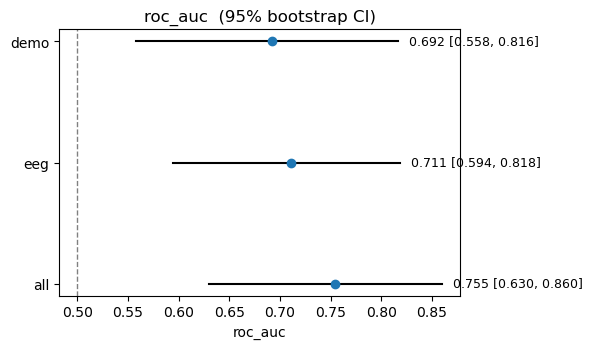

In [98]:
feature_sets = {
    'demo': {'X': X_demo_refined, 'pipeline': models_demo['SVM']['pipeline'],
             'param_grid': models_demo['SVM']['param_grid']},
    'eeg':  {'X': X_power,        'pipeline': models_eeg['SVM']['pipeline'],
             'param_grid': models_eeg['SVM']['param_grid']},
    'all':  {'X': X_all,          'pipeline': models_all['SVM']['pipeline'],
             'param_grid': models_all['SVM']['param_grid']},
}
out = bootstrap_compare_featuresets(feature_sets, y_bdi, inner_cv, outer_cv, n_boot=2000)
plot_forest(out, 'roc_auc')

In [99]:
out['ci_df']

,roc_auc,average_precision,balanced_accuracy,precision,recall,f1,specificity
feature_set,,,,,,,
demo,"0.692 [0.558, 0.816]","0.736 [0.667, 0.864]","0.688 [0.591, 0.784]","0.724 [0.616, 0.837]","0.718 [0.586, 0.846]","0.704 [0.586, 0.799]","0.657 [0.514, 0.800]"
eeg,"0.711 [0.594, 0.818]","0.753 [0.700, 0.859]","0.623 [0.520, 0.720]","0.644 [0.520, 0.775]","0.618 [0.482, 0.746]","0.624 [0.499, 0.730]","0.629 [0.485, 0.771]"
all,"0.755 [0.630, 0.860]","0.808 [0.744, 0.900]","0.689 [0.580, 0.786]","0.711 [0.603, 0.833]","0.693 [0.543, 0.825]","0.700 [0.583, 0.793]","0.686 [0.514, 0.829]"


In [100]:
out['cmp_df']

,metric,comparison,diff,CI,p,sig
0,roc_auc,demo - eeg,-0.019,"[-0.188, +0.155]",0.8650,
1,average_precision,demo - eeg,-0.017,"[-0.135, +0.118]",0.8760,
2,balanced_accuracy,demo - eeg,+0.064,"[-0.077, +0.207]",0.3900,
3,precision,demo - eeg,+0.080,"[-0.098, +0.258]",0.3550,
4,recall,demo - eeg,+0.100,"[-0.089, +0.282]",0.2930,
5,f1,demo - eeg,+0.080,"[-0.081, +0.239]",0.3000,
6,specificity,demo - eeg,+0.029,"[-0.172, +0.257]",0.8540,
7,roc_auc,demo - all,-0.062,"[-0.230, +0.103]",0.4850,
8,average_precision,demo - all,-0.072,"[-0.183, +0.068]",0.3980,
9,balanced_accuracy,demo - all,-0.002,"[-0.146, +0.150]",0.9750,


In [101]:
cfg = feature_sets['demo']
X, y = cfg['X'], np.asarray(y_bdi)

grid = GridSearchCV(clone(cfg['pipeline']), cfg['param_grid'],
                    scoring='roc_auc', cv=inner_cv, n_jobs=-1)

# ONE invocation: authoritative per-fold AUC + the estimators that produced them
res = cross_validate(grid, X, y, cv=outer_cv, scoring='roc_auc',
                     return_estimator=True, n_jobs=1)

recon, params = [], []
for est, (_, te) in zip(res['estimator'], outer_cv.split(X, y)):
    recon.append(roc_auc_score(y[te], est.decision_function(X.iloc[te])))
    params.append(est.best_params_)

print("cross_validate folds:", np.round(res['test_score'], 4), "mean", res['test_score'].mean().round(4))
print("reconstructed  folds:", np.round(recon, 4),            "mean", np.mean(recon).round(4))
print("within-run match:", np.allclose(res['test_score'], recon))
for i, p in enumerate(params):
    print(f"  fold {i} best_params: {p}")

cross_validate folds: [0.7321 0.5714 0.6964 0.7679 0.6939] mean 0.6923
reconstructed  folds: [0.7321 0.5714 0.6964 0.7679 0.6939] mean 0.6923
within-run match: True
  fold 0 best_params: {'clf__C': 20, 'clf__gamma': 0.1, 'select__k': 6}
  fold 1 best_params: {'clf__C': 500, 'clf__gamma': 0.001, 'select__k': 6}
  fold 2 best_params: {'clf__C': 1000, 'clf__gamma': 0.01, 'select__k': 6}
  fold 3 best_params: {'clf__C': 1000, 'clf__gamma': 0.01, 'select__k': 5}
  fold 4 best_params: {'clf__C': 50, 'clf__gamma': 0.05, 'select__k': 6}


In [102]:
# obs, pvals, perm = permutation_test_svm(X_all, y_bdi, models, scoring, n_perm=1000)

# print(obs)

# print(pvals)

# print(perm)

### Feature Analysis

In [103]:
# -----------------------------------------------------------------
# 1. Pick the best model TYPE from the nested-CV results
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'          # match what GridSearchCV optimised
 
mean_scores = {name: res[f'test_{SELECTION_METRIC}'].mean()
               for name, res in all_results.items()}
best_name = max(mean_scores, key=mean_scores.get)
print(f"Best model by mean {SELECTION_METRIC}: "
      f"{best_name} ({mean_scores[best_name]:.3f})")
 
# -----------------------------------------------------------------
# 2. Refit ONE final model on all the data.
#SHAP needs a single model.
# -----------------------------------------------------------------
best_cfg = models_all[best_name]
final_grid = GridSearchCV(
    best_cfg['pipeline'],
    best_cfg['param_grid'],
    scoring=SELECTION_METRIC,
    cv=inner_cv,
    n_jobs=-1,
)
final_grid.fit(X_all, y_bdi)
final_pipe = final_grid.best_estimator_
print("Best hyper-parameters:", final_grid.best_params_)
 

Best model by mean roc_auc: SVM (0.755)
Best hyper-parameters: {'clf__C': 500, 'clf__gamma': 0.001, 'preproc__power__pca__n_components': 10, 'select__k': 13}


In [104]:
# -----------------------------------------------------------------
# 3. Recover the feature matrix that actually reaches the classifier,
#    plus its column names (PCs + demo features) — same logic as the
#    feature-frequency loop, applied to this single model.
# -----------------------------------------------------------------
pca_step = (final_pipe.named_steps['preproc']
                      .named_transformers_['power']
                      .named_steps['pca'])
n_pcs = pca_step.n_components_
 
names_after_preproc = np.array([f'PC{i+1}' for i in range(n_pcs)] + features_demo)
var_mask  = final_pipe.named_steps['var_thresh'].get_support()
names_after_var = names_after_preproc[var_mask]
sel_mask  = final_pipe.named_steps['select'].get_support()
final_feature_names = names_after_var[sel_mask]
 

X_clf = pd.DataFrame(final_pipe[:-1].transform(X_all),
                     columns=final_feature_names)
clf = final_pipe.named_steps['clf']
 

In [105]:
# -----------------------------------------------------------------
# 4. SHAP — pick an explainer that matches the model family
# -----------------------------------------------------------------
if best_name == 'RandomForest':
    explainer   = shap.TreeExplainer(clf)
    explanation = explainer(X_clf, check_additivity=False)
    if explanation.values.ndim == 3:          # (n, feats, classes)
        explanation = explanation[..., 1]     # positive class
 
elif best_name == 'LogisticRegression':
    explainer   = shap.LinearExplainer(clf, X_clf)
    explanation = explainer(X_clf)
 
else:  # SVM (rbf) — no exact explainer; KernelExplainer on P(positive)
    bg = X_clf.sample(min(50, len(X_clf)), random_state=42)
    explainer = shap.KernelExplainer(
        lambda d: clf.predict_proba(d)[:, 1], bg.values
    )
    sv = explainer.shap_values(X_clf.values, nsamples=200)  # slow-ish
    explanation = shap.Explanation(
        values=sv,
        base_values=explainer.expected_value,
        data=X_clf.values,
        feature_names=list(final_feature_names),
    )
 

  0%|          | 0/74 [00:00<?, ?it/s]

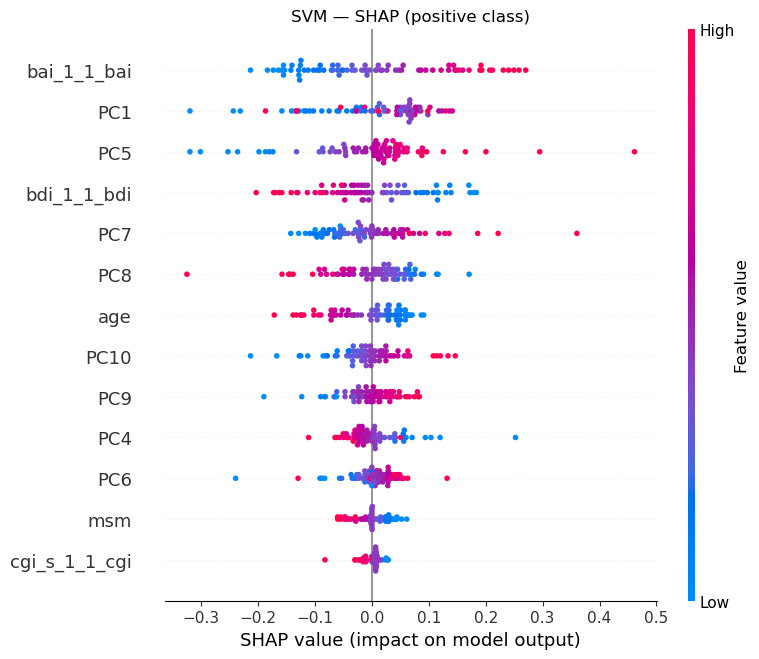

In [106]:
# -----------------------------------------------------------------
# 5. Plots
# -----------------------------------------------------------------
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title(f"{best_name} — SHAP (positive class)")
plt.tight_layout(); plt.savefig('Final_joint_shap_beeswarm.pdf', dpi=150); plt.show()


Mean |SHAP| ranking:
 bai_1_1_bai      0.106803
PC1              0.075475
PC5              0.075415
bdi_1_1_bdi      0.072167
PC7              0.061248
PC8              0.055642
age              0.050937
PC10             0.041908
PC9              0.034694
PC4              0.032750
PC6              0.030262
msm              0.022442
cgi_s_1_1_cgi    0.011036


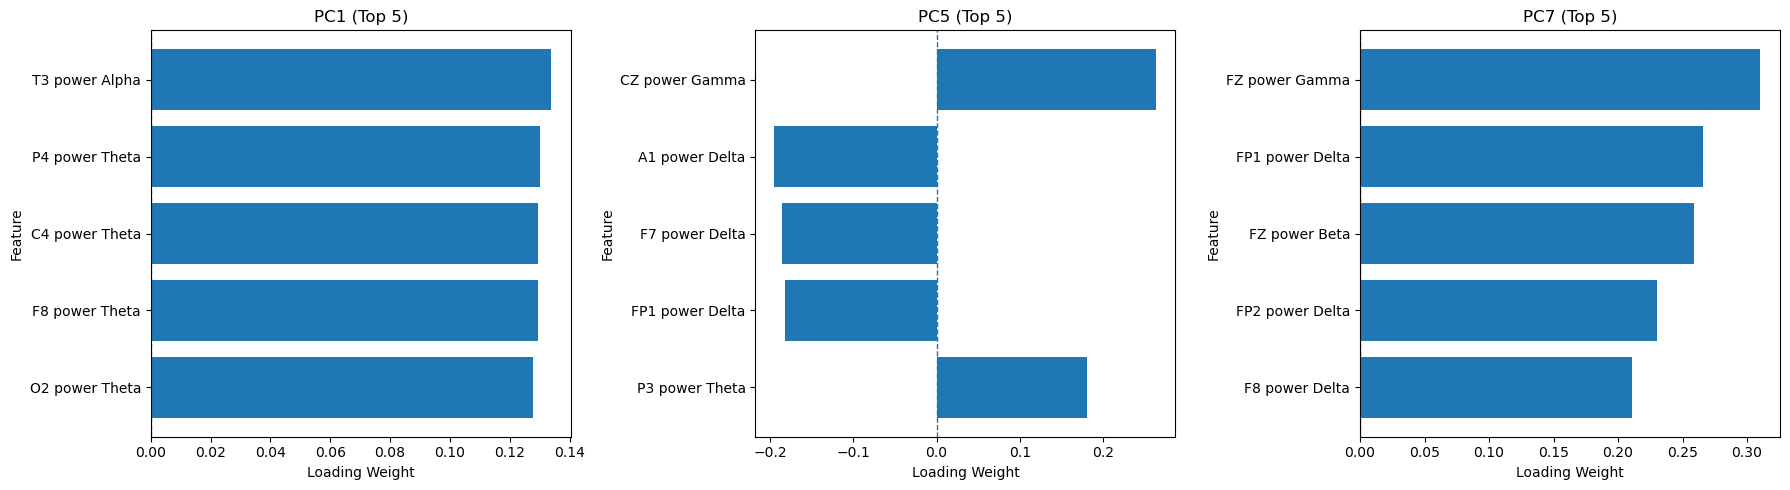

In [107]:
mean_abs = np.abs(explanation.values).mean(axis=0)
ranking = pd.Series(mean_abs, index=final_feature_names).sort_values(ascending=False)
print("\nMean |SHAP| ranking:\n", ranking.to_string())
 
TOP_N = 5
top_pcs = [f for f in ranking.index[:TOP_N] if f.startswith('PC')]
 
 
def plot_top_loadings(loadings, top_pcs, save_path, top_k):
    n = len(top_pcs)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5), sharey=False)
    if n == 1:
        axes = [axes]
 
    for ax, pc in zip(axes, top_pcs):
        pc_index = pc - 1 
        pc_name = loadings.columns[pc_index]
 
        # Top features
        top_features = loadings[pc_name].abs().sort_values(ascending=False).head(top_k).index
        top_weights = loadings.loc[top_features, pc_name]
 
        ax.barh(top_features, top_weights.values)
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.invert_yaxis()  # largest |loading| at the top
 
        ax.set_title(f"{pc_name} (Top {top_k})")
        ax.set_xlabel("Loading Weight")
        ax.set_ylabel("Feature")
 
    plt.tight_layout()
    fig.savefig(save_path, bbox_inches="tight") 
    plt.show()
 
 
if top_pcs:
    # PCs on rows, power features on columns
    loadings = pd.DataFrame(
        pca_step.components_,
        index=[f'PC{i+1}' for i in range(n_pcs)],
        columns=features_power,
    )
    
    top_pc_nums = [int(pc[2:]) for pc in top_pcs]
    plot_top_loadings(loadings.T, top_pc_nums, save_path='Final_joint_pca_loadings.pdf', top_k=5)
else:
    print("\nNo PCs landed in the top ranks — the demo features dominate.")
 

Generating CV curves + confusion matrix for: SVM


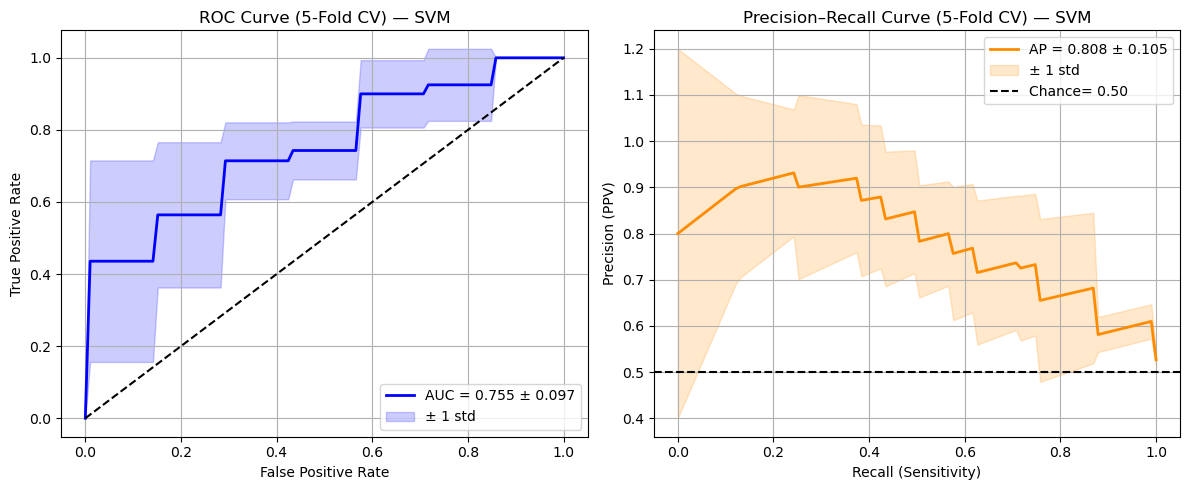

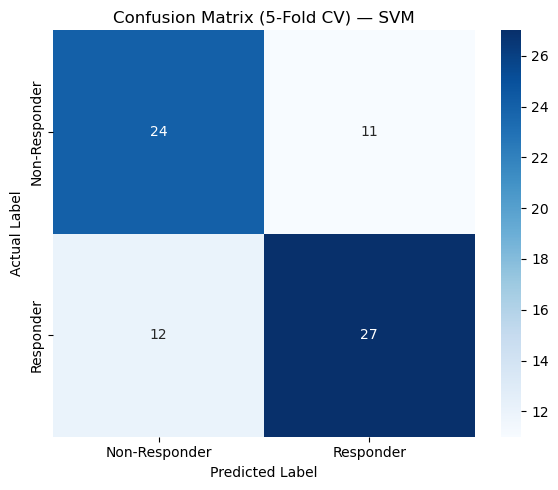

TN=24, FP=11, FN=12, TP=27


In [108]:
# ============================================
# Out-of-fold ROC / PR curves + confusion matrix
# for the best cross-validated model.
# -----------------------------------------------------------------
# Best model type (same selection as the SHAP script)
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'
best_name = max(all_results,
                key=lambda n: all_results[n][f'test_{SELECTION_METRIC}'].mean())
best_cfg = models_all[best_name]
print(f"Generating CV curves + confusion matrix for: {best_name}")

grid = GridSearchCV(best_cfg['pipeline'], best_cfg['param_grid'],
                    scoring=SELECTION_METRIC, cv=inner_cv, n_jobs=-1)


y_arr = np.asarray(y_bdi)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_fpr = np.linspace(0, 1, 100)
mean_recall = np.linspace(0, 1, 100)
tprs, roc_aucs = [], []
precisions, pr_aucs = [], []
y_pred_all = np.zeros(len(y_arr), dtype=int)

for train_idx, test_idx in outer_cv.split(X_all, y_arr):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train, y_test = y_arr[train_idx], y_arr[test_idx]

    grid.fit(X_train, y_train)                       # inner hyper-search, per fold

    y_prob = grid.predict_proba(X_test)[:, 1]
    y_pred_all[test_idx] = grid.predict(X_test)

    # ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_aucs.append(auc(fpr, tpr))

    # PR  
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    precisions.append(np.interp(mean_recall, recall[::-1], precision[::-1]))
    pr_aucs.append(average_precision_score(y_test, y_prob))

# --- Mean curves ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_roc_auc = np.mean(roc_aucs)
std_roc_auc = np.std(roc_aucs)
mean_precision = np.mean(precisions, axis=0)
mean_pr_auc = np.mean(pr_aucs)
std_pr_auc = np.std(pr_aucs)


# -----------------------------------------------------------------
# Figure 1: ROC + PR
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(mean_fpr, mean_tpr, color='blue', lw=2,
             label=f'AUC = {mean_roc_auc:.3f} ± {std_roc_auc:.3f}')
axes[0].fill_between(mean_fpr,
                     mean_tpr - np.std(tprs, axis=0),
                     mean_tpr + np.std(tprs, axis=0),
                     alpha=0.2, color='blue', label='± 1 std')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title(f'ROC Curve (5-Fold CV) — {best_name}')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# PR
axes[1].plot(mean_recall, mean_precision, color='darkorange', lw=2,
             label=f'AP = {mean_pr_auc:.3f} ± {std_pr_auc:.3f}')
axes[1].fill_between(mean_recall,
                     mean_precision - np.std(precisions, axis=0),
                     mean_precision + np.std(precisions, axis=0),
                     alpha=0.2, color='darkorange', label='± 1 std')
axes[1].axhline(y=0.5, color='k', linestyle='--',
                label=f'Chance= {0.5:.2f}')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title(f'Precision–Recall Curve (5-Fold CV) — {best_name}')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('Final_joint_ROC_PRC_5fold.pdf')
plt.show()

# -----------------------------------------------------------------
# Figure 2: confusion matrix on all out-of-fold predictions
# -----------------------------------------------------------------
cm = confusion_matrix(y_arr, y_pred_all)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Responder', 'Responder'],
            yticklabels=['Non-Responder', 'Responder'])
plt.title(f'Confusion Matrix (5-Fold CV) — {best_name}')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('Final_joint_ConfuseMtrx.pdf')
plt.show()

print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Calibration + DCA for: SVM
Best hyper-parameters: {'clf__C': 500, 'clf__gamma': 0.001, 'preproc__power__pca__n_components': 10, 'select__k': 13}


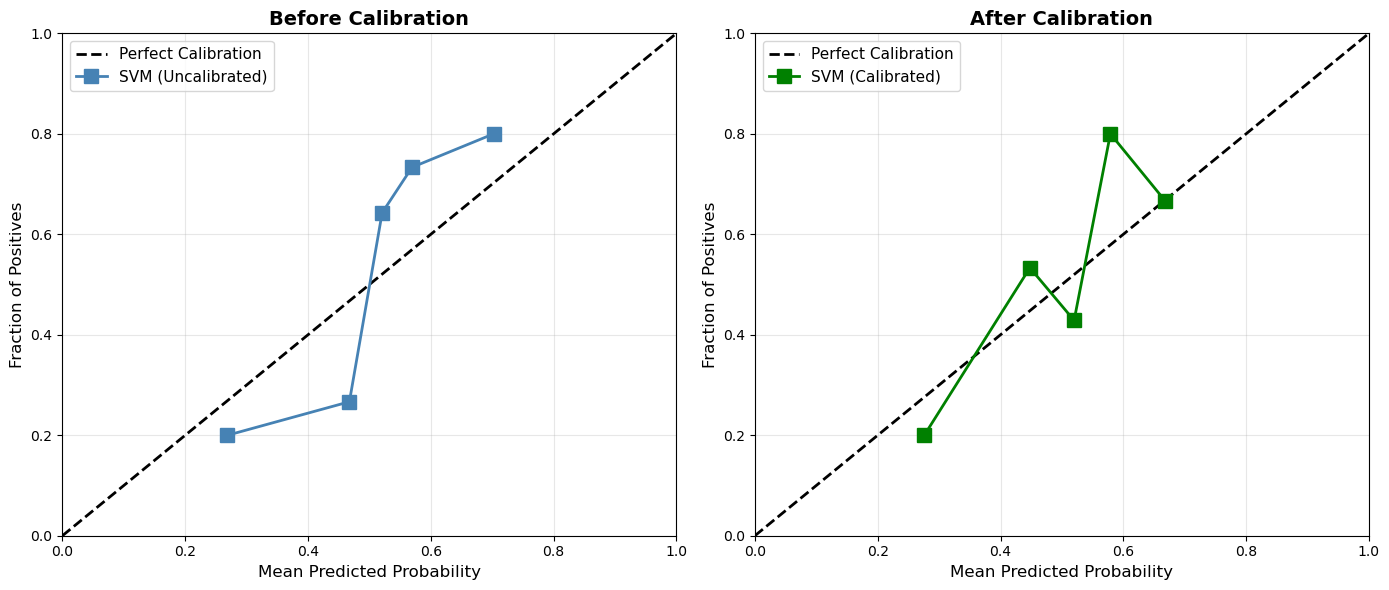


=== Hosmer-Lemeshow Test ===
Uncalibrated: HL chi2 = 9.12, p = 0.3322 (df=8)
Calibrated:   HL chi2 = 8.40, p = 0.3957 (df=8)
(higher p = better fit; p>0.05 => no significant miscalibration)


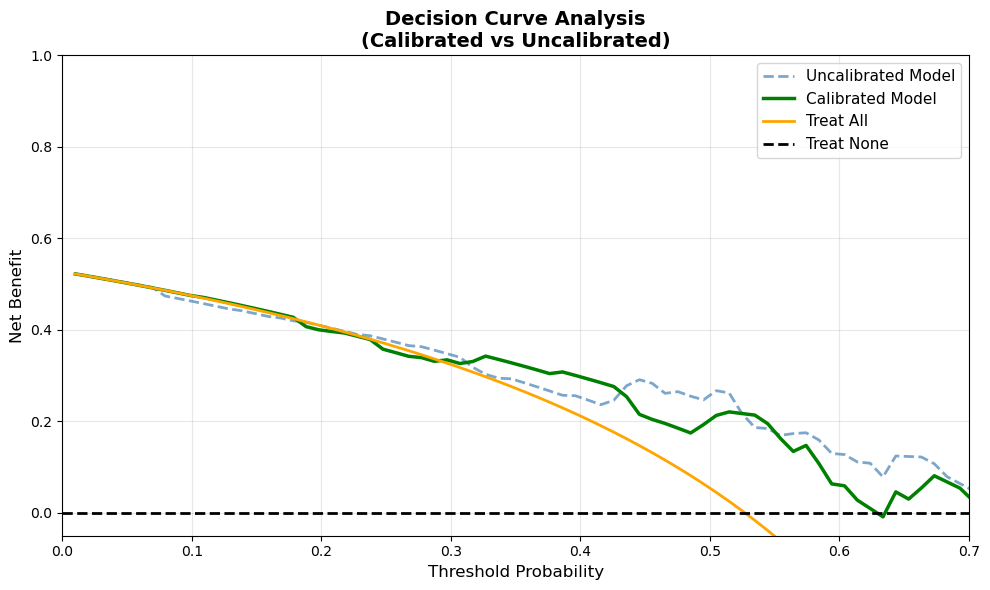

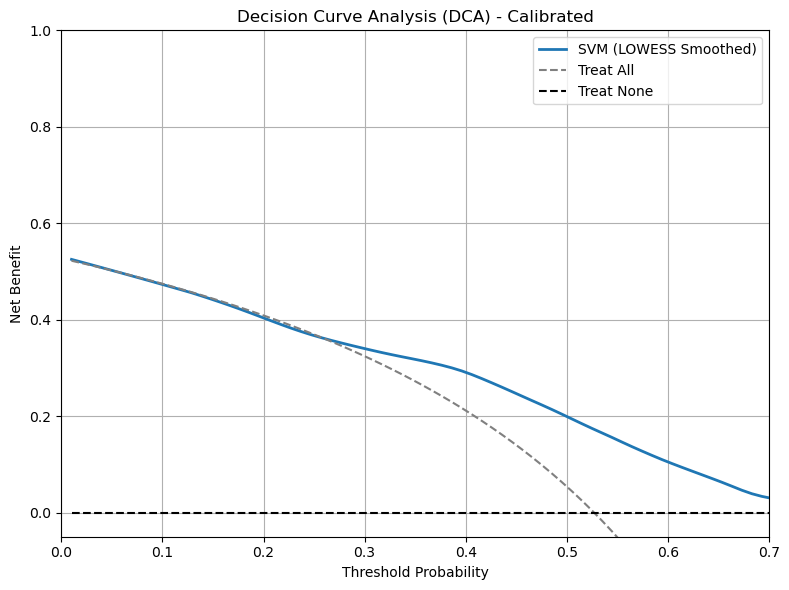


Model beats both references between threshold 0.010 and 0.921 (non-contiguous).

Closest threshold: 0.446
Model net benefit:     0.2510
Treat-all net benefit: 0.1469
Difference (Model - Treat All): 0.1041


In [109]:
try:
    from statsmodels.nonparametric.smoothers_lowess import lowess
    _HAS_LOWESS = True
except Exception:
    _HAS_LOWESS = False

# -----------------------------------------------------------------
# Best model (same selection as the SHAP / curves scripts)
# -----------------------------------------------------------------
SELECTION_METRIC = 'roc_auc'
best_name = max(all_results,
                key=lambda n: all_results[n][f'test_{SELECTION_METRIC}'].mean())
best_cfg = models_all[best_name]
print(f"Calibration + DCA for: {best_name}")

# Fix hyper-parameters once, then reuse a clone per fold.
# (Calibration assesses probability quality, not model selection; this keeps
#  the loop tractable. For fully-nested selection inside calibration, replace
#  `clone(best_pipe)` below with a fresh GridSearchCV(best_cfg[...]) — far slower.)
final_grid = GridSearchCV(best_cfg['pipeline'], best_cfg['param_grid'],
                          scoring=SELECTION_METRIC, cv=inner_cv, n_jobs=-1)
final_grid.fit(X_all, y_bdi)
best_pipe = final_grid.best_estimator_
print("Best hyper-parameters:", final_grid.best_params_)

# -----------------------------------------------------------------
# Out-of-fold probabilities: uncalibrated vs sigmoid-calibrated
# -----------------------------------------------------------------
y_arr = np.asarray(y_bdi)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_proba_uncal = np.zeros(len(y_arr))
y_proba_cal = np.zeros(len(y_arr))

for train_idx, test_idx in outer_cv.split(X_all, y_arr):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train = y_arr[train_idx]

    # Uncalibrated
    uncal = clone(best_pipe).fit(X_train, y_train)
    y_proba_uncal[test_idx] = uncal.predict_proba(X_test)[:, 1]

    # Calibrated (calibration fit only on the training fold)
    cal = CalibratedClassifierCV(clone(best_pipe), method='sigmoid', cv=3)
    cal.fit(X_train, y_train)
    y_proba_cal[test_idx] = cal.predict_proba(X_test)[:, 1]

# -----------------------------------------------------------------
# Calibration curves: before vs after
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, proba, color, label, title in [
    (axes[0], y_proba_uncal, 'steelblue', f'{best_name} (Uncalibrated)', 'Before Calibration'),
    (axes[1], y_proba_cal,   'green',     f'{best_name} (Calibrated)',   'After Calibration'),
]:
    prob_true, prob_pred = calibration_curve(y_arr, proba, n_bins=5, strategy='quantile')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
    ax.plot(prob_pred, prob_true, 's-', linewidth=2, markersize=10, color=color, label=label)
    ax.set_xlabel('Mean Predicted Probability', fontsize=12)
    ax.set_ylabel('Fraction of Positives', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig('Final_joint_Calibration_5fold.pdf')
plt.show()

# -----------------------------------------------------------------
# Hosmer-Lemeshow goodness-of-fit
# -----------------------------------------------------------------
def hosmer_lemeshow(y_true, y_prob, g=10):
    data = pd.DataFrame({'y': np.asarray(y_true), 'p': np.asarray(y_prob)})
    data['group'] = pd.qcut(data['p'], q=g, duplicates='drop')
    obs = data.groupby('group', observed=True)['y'].sum()
    exp = data.groupby('group', observed=True)['p'].sum()
    n = data.groupby('group', observed=True)['y'].count()
    hl_stat = np.sum((obs - exp) ** 2 / (exp * (1 - exp / n)))
    dof = data['group'].nunique() - 2          # actual groups, not g
    if dof < 1:
        return hl_stat, np.nan, dof
    return hl_stat, 1 - chi2.cdf(hl_stat, dof), dof

hl_uncal, p_uncal, df_uncal = hosmer_lemeshow(y_arr, y_proba_uncal)
hl_cal, p_cal, df_cal = hosmer_lemeshow(y_arr, y_proba_cal)
print("\n=== Hosmer-Lemeshow Test ===")
print(f"Uncalibrated: HL chi2 = {hl_uncal:.2f}, p = {p_uncal:.4f} (df={df_uncal})")
print(f"Calibrated:   HL chi2 = {hl_cal:.2f}, p = {p_cal:.4f} (df={df_cal})")
print("(higher p = better fit; p>0.05 => no significant miscalibration)")

# -----------------------------------------------------------------
# Decision Curve Analysis (net benefit, Vickers & Elkin)
# -----------------------------------------------------------------
def decision_curve(y_true, y_prob, thresholds):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    n = len(y_true); prev = y_true.mean()
    rows = []
    for pt in thresholds:
        pred_pos = y_prob >= pt
        tp = np.sum(pred_pos & (y_true == 1))
        fp = np.sum(pred_pos & (y_true == 0))
        w = pt / (1 - pt)
        nb_model = tp / n - (fp / n) * w
        nb_all = prev - (1 - prev) * w
        rows.append((pt, nb_model, nb_all, 0.0))
    return pd.DataFrame(rows, columns=['Threshold', 'NetBenefit_Model',
                                       'NetBenefit_All', 'NetBenefit_None'])

thr_grid = np.linspace(0.01, 0.99, 100)
dca_uncal = decision_curve(y_arr, y_proba_uncal, thr_grid)
dca_cal = decision_curve(y_arr, y_proba_cal, thr_grid)

# --- Calibrated vs uncalibrated, with reference strategies ---
plt.figure(figsize=(10, 6))
plt.plot(dca_uncal['Threshold'], dca_uncal['NetBenefit_Model'], '--',
         color='steelblue', lw=2, alpha=0.7, label='Uncalibrated Model')
plt.plot(dca_cal['Threshold'], dca_cal['NetBenefit_Model'],
         color='green', lw=2.5, label='Calibrated Model')
plt.plot(dca_cal['Threshold'], dca_cal['NetBenefit_All'],
         color='orange', lw=2, label='Treat All')
plt.axhline(y=0, color='black', linestyle='--', lw=2, label='Treat None')
plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.xlabel('Threshold Probability', fontsize=12)
plt.ylabel('Net Benefit', fontsize=12)
plt.title('Decision Curve Analysis\n(Calibrated vs Uncalibrated)',
          fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('DCA_cal_vs_uncal.pdf')
plt.show()

# --- LOWESS-smoothed calibrated curve ---
dca_df = dca_cal
dca_x = dca_df['Threshold'].values
dca_y = dca_df['NetBenefit_Model'].values

if _HAS_LOWESS:
    smoothed = lowess(dca_y, dca_x, frac=0.25)   # frac: 0.1 light .. 0.3 strong
    x_smooth, y_smooth = smoothed[:, 0], smoothed[:, 1]
else:
    x_smooth, y_smooth = dca_x, dca_y
    print("statsmodels not installed -> showing raw calibrated DCA "
          "(pip install statsmodels for LOWESS smoothing).")

plt.figure(figsize=(8, 6))
plt.plot(x_smooth, y_smooth, lw=2,
         label=f'{best_name} ({"LOWESS Smoothed" if _HAS_LOWESS else "raw"})')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_All'], '--', color='gray', label='Treat All')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_None'], '--', color='black', label='Treat None')
plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis (DCA) - Calibrated')
plt.xlim(0, 0.7)
plt.ylim(-0.05, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('Final_joint_SmoothedDCA.pdf')
plt.show()

# -----------------------------------------------------------------
# Where does the model beat BOTH references? (compare net benefit, y_smooth)
# -----------------------------------------------------------------
nb_all = dca_df['NetBenefit_All'].values          # aligned with x_smooth (sorted grid)
better_than_all = y_smooth > nb_all
better_than_none = y_smooth > 0.0
superior = np.where(better_than_all & better_than_none)[0]

if superior.size:
    th = dca_df['Threshold'].values[superior]
    print(f"\nModel beats both references between threshold "
          f"{th.min():.3f} and {th.max():.3f}"
          f"{' (non-contiguous)' if np.any(np.diff(superior) > 1) else ''}.")
else:
    print("\nModel never strictly beats both references in this range.")

# --- Net benefit at a clinical threshold of interest ---
thr = 0.45
idx = int(np.argmin(np.abs(dca_df['Threshold'].values - thr)))
model_nb = y_smooth[idx]
treat_all_nb = dca_df['NetBenefit_All'].values[idx]
print(f"\nClosest threshold: {dca_df['Threshold'].values[idx]:.3f}")
print(f"Model net benefit:     {model_nb:.4f}")
print(f"Treat-all net benefit: {treat_all_nb:.4f}")
print(f"Difference (Model - Treat All): {model_nb - treat_all_nb:.4f}")

## Validation on NewBlossom

In [110]:
newBlossom = pd.read_csv('BLOSSOM_restingState_13-Mar-2026_nonZ.csv')

In [111]:
newBlossom = newBlossom.dropna(how='all')

In [112]:
newBlossom_demo_1 = pd.read_excel('MGH EEG Project data (2025.12).xlsx')
newBlossom_demo_2 = pd.read_excel('MGH EEG Project data (2025.12)_012926.xlsx')
newBlossom_demo_complete = pd.read_excel('MGH_EEG_Project_Data_Prospective_Outcomes.xlsx')

In [113]:
newBlossom = newBlossom.drop(columns=['WPE'])

In [114]:
Rest_Blossom_tmp = pd.read_csv('BLOSSOM_restingState_23-Nov-2024_nonZ.csv')

In [115]:
common_features = list(set(np.unique(newBlossom.Channel.values)) & set(np.unique(Rest_Blossom_tmp.Channel.values)))

In [116]:
common_features;

In [117]:
diff_features = list(set(np.unique(newBlossom.Channel.values))-(set(np.unique(Rest_Blossom_tmp.Channel.values))))

In [118]:
diff_features

[]

In [119]:
common_features;

In [120]:
len(common_features)

21

In [121]:
newBlossom = newBlossom[newBlossom["Channel"].isin(common_features)]

In [122]:
newBlossom_Completer_IDs = newBlossom_demo_complete.ID.values

In [123]:
newBlossom_Completer_IDs

array([ 501, 7449, 7966, 8150, 8390, 8703, 8744, 8789, 8792, 8858, 8861,
       8873, 8885, 8897, 8909, 8913, 8920, 8928, 8944, 8951, 8959, 8967,
       9025, 9051, 9109, 9129, 9154, 9161, 9211, 9229, 9243, 7674, 8011,
       7866, 6297, 6298, 6311, 6321, 6360, 6485, 6909, 6977, 6573])

In [124]:
newBlossom['Subject'] = newBlossom['Subject'].str.replace('sub-', '', regex=False)

In [125]:
newBlossom = newBlossom.rename(columns={'Subject': 'id'})

In [126]:
newBlossom['id'] = newBlossom['id'].astype(str)

In [127]:
newBlossom_IDS = np.unique(newBlossom.id)

In [128]:
newBlossom_IDS = [int(x) for x in newBlossom_IDS]

In [129]:
len(newBlossom_Completer_IDs)

43

In [130]:
common = list(set(newBlossom_Completer_IDs) & set(newBlossom_IDS))
print(common)

[8703, 9109, 6297, 6298, 8858, 8861, 7966, 6311, 8744, 8873, 9129, 6573, 6321, 8885, 7866, 6977, 9154, 8390, 8011, 8913, 8789, 6485, 8920, 8792, 6360, 8928, 501, 7674, 6909, 8959]


In [131]:
newBlossom_demo_complete_PHQ = newBlossom_demo_complete[["ID", "Pre-PHQ", "Post-PHQ\n(2-12)"]]

In [132]:
newBlossom_demo_complete_PHQ=newBlossom_demo_complete_PHQ.dropna().reset_index()

In [133]:
ID_to_remove = newBlossom_demo_complete_PHQ.iloc[15].ID

In [134]:
ID_to_remove

9051

In [135]:
newBlossom_demo_complete_PHQ=newBlossom_demo_complete_PHQ.drop(15)

In [136]:
newBlossom_demo_complete_gender_age = newBlossom_demo_complete[['ID','Gender', 'Age', 'Pre-PHQ','Post-PHQ\n(1-12)','Post-PHQ\n(2-12)','Stimulation Brain Area']]

In [137]:
newBlossom_demo_complete_gender_age=newBlossom_demo_complete_gender_age.dropna(subset=['Post-PHQ\n(2-12)','Pre-PHQ'])

In [138]:
newBlossom_demo_complete_gender_age=newBlossom_demo_complete_gender_age.drop(index=23)

In [139]:
newBlossom_demo_complete_PHQ['PHQ_responder'] =  (((newBlossom_demo_complete_PHQ['Pre-PHQ'] - newBlossom_demo_complete_PHQ['Post-PHQ\n(2-12)']) / newBlossom_demo_complete_PHQ['Pre-PHQ']) >= 0.50).astype(int)

In [140]:
newBlossom_demo_complete_PHQ.ID.values

array([ 501, 7966, 8390, 8703, 8744, 8789, 8792, 8858, 8861, 8873, 8885,
       8913, 8920, 8928, 8959, 9109, 9129, 9154, 7674, 8011, 7866, 6297,
       6298, 6311, 6321, 6360, 6485, 6909, 6977, 6573])

In [141]:
common = list(set(newBlossom_demo_complete_PHQ.ID.values) &set(common))
print(common)

[8703, 9109, 6297, 6298, 8858, 8861, 7966, 6311, 8744, 8873, 9129, 6573, 6321, 8885, 7866, 6977, 9154, 8390, 8011, 8913, 8789, 6485, 8920, 8792, 6360, 8928, 501, 7674, 6909, 8959]


In [142]:
newBlossom_demo_complete_PHQ = newBlossom_demo_complete_PHQ[newBlossom_demo_complete_PHQ["ID"].isin(common)]

In [143]:
newBlossom_demo_complete_PHQ = newBlossom_demo_complete_PHQ.sort_values(by="ID")


In [144]:
y_newBlossom = newBlossom_demo_complete_PHQ.PHQ_responder.values

In [145]:
len(y_newBlossom)

30

In [146]:
newBlossom_demo_complete_gender_age = newBlossom_demo_complete_gender_age.merge(newBlossom_demo_complete_PHQ[['ID', 'PHQ_responder']], on='ID', how='left')

In [147]:
newBlossom_demo_complete_gender_age.to_csv('preprocessed_prospective_validation_data.csv')

In [148]:
columns = ['Gender',	'Age',	'Pre-PHQ',	'Post-PHQ\n(1-12)',	'Post-PHQ\n(2-12)',	'Stimulation Brain Area']      
categorical = ['Gender','Stimulation Brain Area']                             
groupby = 'PHQ_responder'  

mytable = TableOne(data=newBlossom_demo_complete_gender_age,
                   columns=columns,
                   categorical=categorical,
                   groupby=groupby,
                   missing = False,
                   pval=True)

print(mytable.tabulate(tablefmt="fancy_grid"))

╒═══════════════════════════════╤════════════════════╤═════════════╤═════════════╤═════════════╤═══════════╕
│                               │                    │ Overall     │ 0           │ 1           │ P-Value   │
╞═══════════════════════════════╪════════════════════╪═════════════╪═════════════╪═════════════╪═══════════╡
│ n                             │                    │ 30          │ 15          │ 15          │           │
├───────────────────────────────┼────────────────────┼─────────────┼─────────────┼─────────────┼───────────┤
│ Gender, n (%)                 │ F                  │ 13 (43.3)   │ 8 (53.3)    │ 5 (33.3)    │ 0.461     │
├───────────────────────────────┼────────────────────┼─────────────┼─────────────┼─────────────┼───────────┤
│                               │ M                  │ 17 (56.7)   │ 7 (46.7)    │ 10 (66.7)   │           │
├───────────────────────────────┼────────────────────┼─────────────┼─────────────┼─────────────┼───────────┤
│ Age, mean (SD)   

In [149]:
mytable.to_excel('TableOne_NewBlossom.xlsx')

In [150]:
newBlossom["id"] = newBlossom["id"].astype(int)

In [151]:
newBlossom = newBlossom[newBlossom["id"].isin(common)]

In [152]:
newBlossom = newBlossom.dropna()

In [153]:
newBlossom = newBlossom.copy()
newBlossom['Channel'] = newBlossom['Channel'].astype(str).str.strip().str.upper()
newBlossom['FreqBand'] = newBlossom['FreqBand'].astype(str).str.strip().str.capitalize()


In [154]:
newBlossom['feature'] = newBlossom['Channel'] + ' power ' + newBlossom['FreqBand']

In [155]:
newBlossom = newBlossom.drop_duplicates(subset=['id','Session', 'Channel', 'FreqBand'], keep='first')

In [156]:
newBlossom['feature'] = newBlossom['Channel'] + ' power ' + newBlossom['FreqBand']
newBlossom = newBlossom.pivot(index='id', columns='feature', values='Abs_Power')#.reset_index()

In [157]:
missing_features = set(X_power.columns.values) - set(newBlossom.columns.values)

In [158]:
missing_features

set()

In [159]:
alpha = 0.05
num_cols = X_power.select_dtypes(include="number").columns.intersection(newBlossom.select_dtypes(include="number").columns)

rows = []
for col in num_cols:
    stat, p = ks_2samp(X_power[col].dropna(), newBlossom[col].dropna())
    rows.append({"feature": col, "ks_stat": stat, "p_value": p})

res = pd.DataFrame(rows)

# FDR correction across all tested features
res["p_adj_fdr"] = multipletests(res["p_value"].values, alpha=alpha, method="fdr_bh")[1]

# Binary decisions
res["homogeneous_raw"] = res["p_value"] > alpha
res["homogeneous_fdr"] = res["p_adj_fdr"] > alpha



In [160]:
newBlossom = newBlossom.sort_values(by="id")

In [161]:
common_features = list(set(X_power.columns) & set(newBlossom.columns))

In [162]:
common_features = X_power.columns.intersection(newBlossom.columns)

In [163]:
X_newBlossom = np.log1p(newBlossom[common_features])

In [164]:
y_pred = pipe_best_eeg.predict(X_newBlossom)


In [165]:
# Get probability predictions instead
y_proba = pipe_best_eeg.predict_proba(X_newBlossom)[:, 1]

In [166]:
tn, fp, fn, tp = confusion_matrix(y_newBlossom, y_pred).ravel()
specificity = tn / (tn + fp)

print("=== Validation Set Performance ===")
print(f"{'Balanced Accuracy':20s}: {balanced_accuracy_score(y_newBlossom, y_pred):.3f}")
print(f"{'ROC AUC':20s}: {roc_auc_score(y_newBlossom, y_proba):.3f}")
print(f"{'F1':20s}: {f1_score(y_newBlossom, y_pred):.3f}")
print(f"{'Precision':20s}: {precision_score(y_newBlossom, y_pred):.3f}")
print(f"{'Recall':20s}: {recall_score(y_newBlossom, y_pred):.3f}")
print(f"{'Specificity':20s}: {specificity:.3f}")
print(f"\nTN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("\n" + classification_report(y_newBlossom, y_pred,
                                   target_names=['Non-Responder', 'Responder']))

=== Validation Set Performance ===
Balanced Accuracy   : 0.667
ROC AUC             : 0.671
F1                  : 0.615
Precision           : 0.727
Recall              : 0.533
Specificity         : 0.800

TN=12, FP=3, FN=7, TP=8

               precision    recall  f1-score   support

Non-Responder       0.63      0.80      0.71        15
    Responder       0.73      0.53      0.62        15

     accuracy                           0.67        30
    macro avg       0.68      0.67      0.66        30
 weighted avg       0.68      0.67      0.66        30



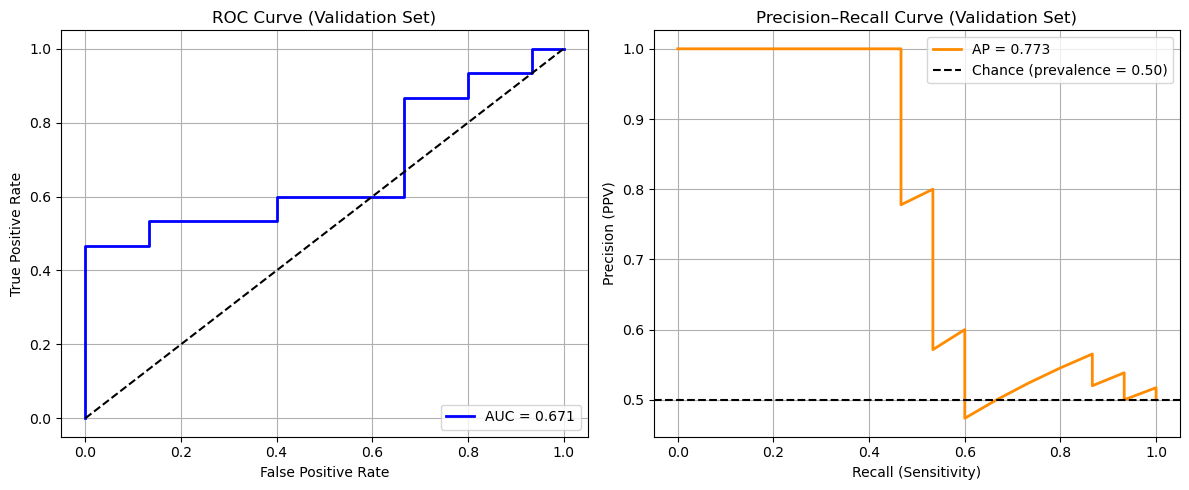

In [167]:
fpr, tpr, _ = roc_curve(y_newBlossom, y_proba)
roc_auc = auc(fpr, tpr)
prevalence = np.mean(y_newBlossom)
precision, recall, _ = precision_recall_curve(y_newBlossom, y_proba)
pr_auc = average_precision_score(y_newBlossom, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'AUC = {roc_auc:.3f}')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Validation Set)')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# PR
axes[1].plot(recall, precision, color='darkorange', lw=2, label=f'AP = {pr_auc:.3f}')
axes[1].axhline(y=prevalence, color='k', linestyle='--',
                label=f'Chance (prevalence = {prevalence:.2f})')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision–Recall Curve (Validation Set)')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('Final_Prospective_ROC_PRC_validation.pdf')
plt.show()

In [168]:
print("Precision:", precision_score(y_newBlossom, y_pred))
print("Recall:", recall_score(y_newBlossom, y_pred))

Precision: 0.7272727272727273
Recall: 0.5333333333333333


In [169]:
def permutation_test_prospective(model, X_test, y_test, metric_fn,
                                 n_perm=1000, greater_is_better=True,
                                 random_state=42):
    rng = np.random.default_rng(random_state)

    if hasattr(model, "predict_proba"):
        y_pred = model.predict_proba(X_test)[:, 1]
    else:
        y_pred = model.predict(X_test)

    y_test = np.asarray(y_test)
    M_real = metric_fn(y_test, y_pred)

    perm_scores = np.empty(n_perm)
    for i in range(n_perm):
        perm_scores[i] = metric_fn(rng.permutation(y_test), y_pred)

    if greater_is_better:
        p_value = (1 + np.sum(perm_scores >= M_real)) / (n_perm + 1)
    else:
        p_value = (1 + np.sum(perm_scores <= M_real)) / (n_perm + 1)

    return M_real, perm_scores, p_value

In [170]:
M_real, perm_scores, p_value = permutation_test_prospective(
    model=pipe_best_eeg,
    X_test=X_newBlossom,
    y_test=y_newBlossom,
    metric_fn=roc_auc_score,
    n_perm=1000,
    greater_is_better=True,
    random_state=42,
)

In [171]:
M_real

0.6711111111111111

In [172]:
p_value

0.055944055944055944

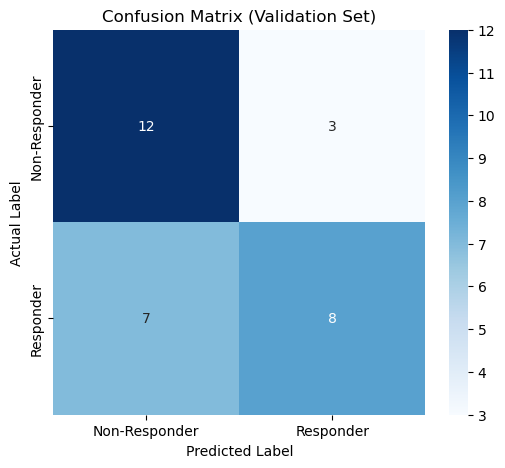

TN=12, FP=3, FN=7, TP=8


In [173]:
cm = confusion_matrix(y_newBlossom, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Responder', 'Responder'],
            yticklabels=['Non-Responder', 'Responder'])
plt.title('Confusion Matrix (Validation Set)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.savefig('Final_Prospective_ConfuseMtrx.pdf')
plt.show()

print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

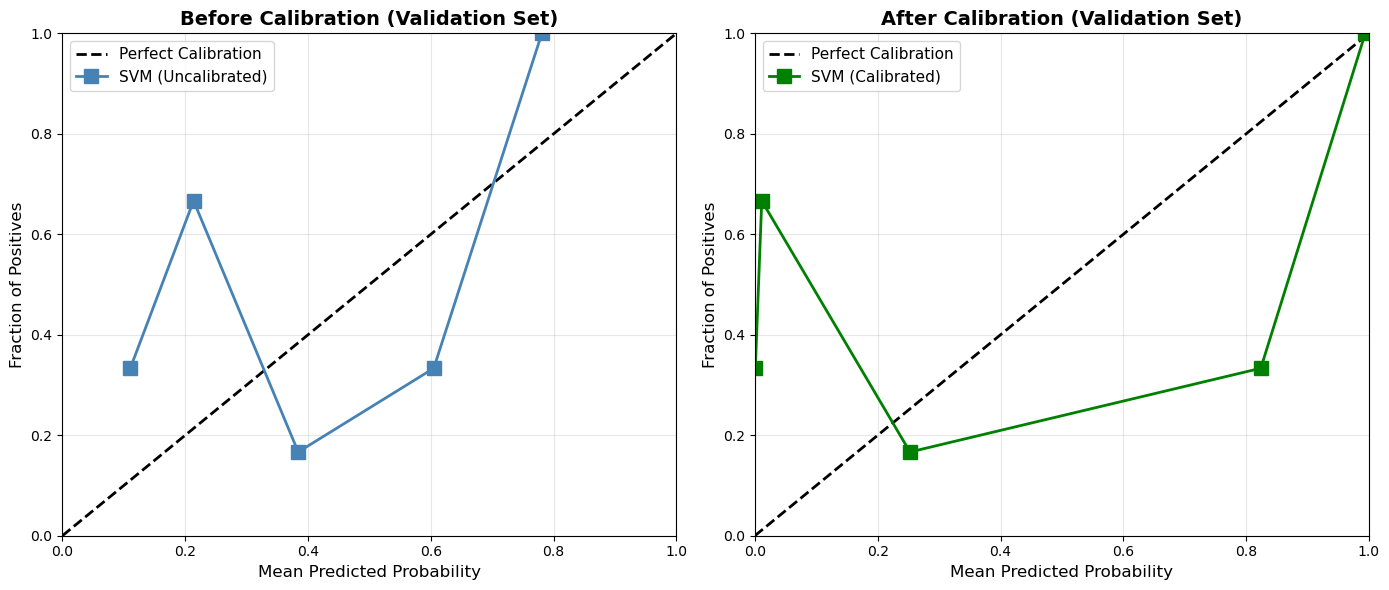

In [174]:
# ============================================
# Fit final model on ALL training data
# ============================================
# grid.fit(X_power, y_bdi)
# best_pipe = grid.best_estimator_  # full pipeline: scaler + pca + svc

# ============================================
# Uncalibrated predictions — from best_pipe directly
# ============================================
y_proba_uncal = pipe_best_eeg.predict_proba(X_newBlossom)[:, 1]

# ============================================
# Calibrated predictions — wrap the SAME pipeline
# cv='prefit' means: don't refit, just learn the calibration layer
# on the training data using the already-fitted best_pipe
# ============================================
calibrated_final = CalibratedClassifierCV(pipe_best_eeg, method='sigmoid', cv='prefit')
calibrated_final.fit(X_power, y_bdi)  # only fits the sigmoid layer, not the pipeline
y_proba_cal = calibrated_final.predict_proba(X_newBlossom)[:, 1]

# ============================================
# Compare Calibration
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prob_true_uncal, prob_pred_uncal = calibration_curve(
    y_newBlossom, y_proba_uncal, n_bins=5, strategy='quantile'
)
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
axes[0].plot(prob_pred_uncal, prob_true_uncal, 's-', linewidth=2,
             markersize=10, color='steelblue', label='SVM (Uncalibrated)')
axes[0].set_xlabel('Mean Predicted Probability', fontsize=12)
axes[0].set_ylabel('Fraction of Positives', fontsize=12)
axes[0].set_title('Before Calibration (Validation Set)', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1])

prob_true_cal, prob_pred_cal = calibration_curve(
    y_newBlossom, y_proba_cal, n_bins=5, strategy='quantile'
)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect Calibration')
axes[1].plot(prob_pred_cal, prob_true_cal, 's-', linewidth=2,
             markersize=10, color='green', label='SVM (Calibrated)')
axes[1].set_xlabel('Mean Predicted Probability', fontsize=12)
axes[1].set_ylabel('Fraction of Positives', fontsize=12)
axes[1].set_title('After Calibration (Validation Set)', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.savefig('Final_Prospective_Calibration.pdf')
plt.show()

In [175]:
thresh_uncal, nb_uncal, nb_all = decision_curve_analysis(y_newBlossom, y_proba_uncal)
thresh_cal, nb_cal, _ = decision_curve_analysis(y_newBlossom, y_proba_cal)

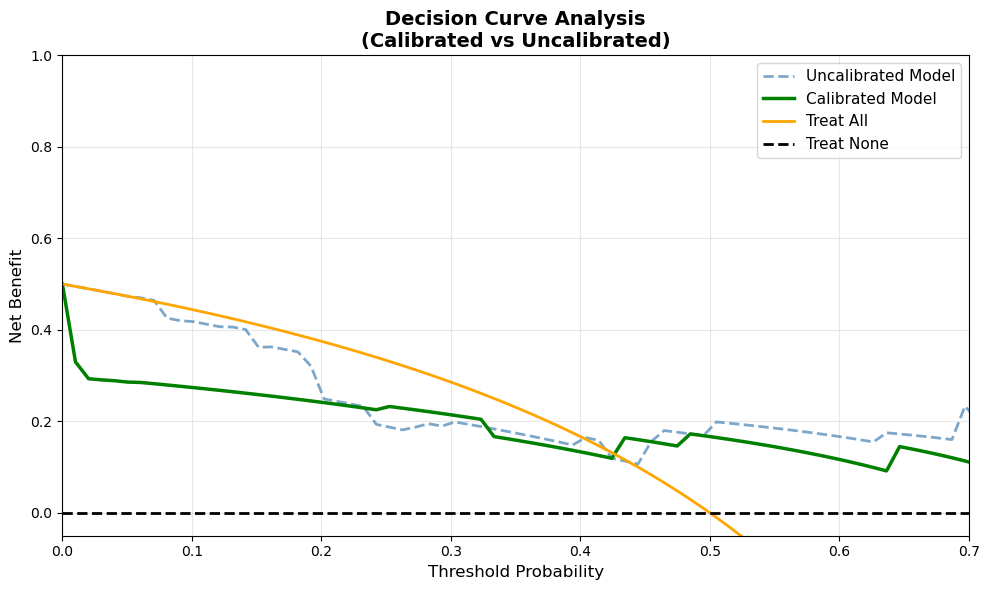

In [176]:
plt.figure(figsize=(10, 6))
plt.plot(thresh_uncal, nb_uncal, linewidth=2, color='steelblue', 
         label='Uncalibrated Model', linestyle='--', alpha=0.7)
plt.plot(thresh_cal, nb_cal, linewidth=2.5, color='green', 
         label='Calibrated Model')
plt.plot(thresh_cal, nb_all, linewidth=2, color='orange', 
         label='Treat All')
plt.axhline(y=0, color='black', linestyle='--', linewidth=2, 
            label='Treat None')

plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.xlabel('Threshold Probability', fontsize=12)
plt.ylabel('Net Benefit', fontsize=12)
plt.title('Decision Curve Analysis\n(Calibrated vs Uncalibrated)', 
          fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()


In [177]:
dca_df = decision_curve(y_newBlossom, y_proba, thresholds=np.linspace(0.01, 0.99, 100))

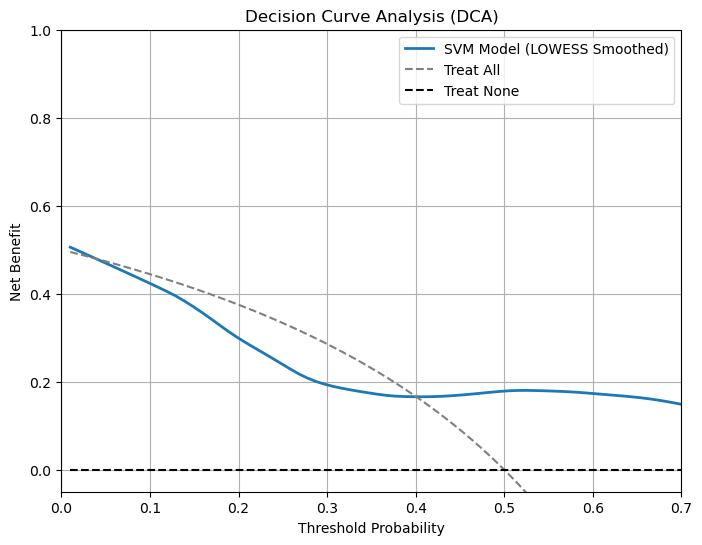

In [178]:
dca_x = dca_df["Threshold"].values
dca_y = dca_df["NetBenefit_Model"].values

# frac controls smoothing: 0.1 = modest smoothing, 0.3 = strong smoothing
smoothed = lowess(dca_y, dca_x, frac=0.25)

x_smooth = smoothed[:, 0]
y_smooth = smoothed[:, 1]

plt.figure(figsize=(8, 6))

plt.plot(x_smooth, y_smooth, label='SVM Model (LOWESS Smoothed)', lw=2)

plt.plot(dca_df['Threshold'], dca_df['NetBenefit_All'], linestyle='--', color='gray', label='Treat All')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_None'], linestyle='--', color='black', label='Treat None')

plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis (DCA)')
plt.ylim(-0.05, 1)
plt.xlim(0, 0.7)
plt.legend()
plt.grid(True)
plt.savefig('Final_Prospective_SmoothedDCA.pdf')
plt.show()

## TD Brain

In [179]:
tdBrain = pd.read_csv('TDBrain_restingState_13-Feb-2025_nonZ_correctedGenderAge.csv')

In [180]:
tdBrain[tdBrain['BDI_POST'].notna()].nunique()

Dataset                   2
Subject                 123
Indication                3
Population                1
BDI_MDD                   1
BDI_PRE                  39
BDI_POST                 43
rTMS_protocol             3
Task                      2
Session                   2
Channel                  26
FreqBand                  5
Abs_Power             30676
Rel_Power             30040
FOOOF_1_45             5288
FOOOF_1_45_offset      6688
FOOOF_30_45            6111
FOOOF_30_35_offset     6658
WPE                       0
Oscillatory_Pow       23906
age                     120
gender                    2
NeoAnxiety_Pre           14
NeoAnxiety_Post           5
NeoDepression_Pre        15
NeoDepression_Post        5
dtype: int64

In [181]:
tdBrain = tdBrain[(tdBrain['Population'] == 'MDD') & (tdBrain['Task'] == 'EC')]

In [182]:
tdBrain = tdBrain[tdBrain['rTMS_protocol'] != 3]

In [183]:
tdBrain['Channel'] = tdBrain['Channel'].astype(str).str.strip().str.upper()
tdBrain['FreqBand'] = tdBrain['FreqBand'].astype(str).str.strip().str.capitalize()
tdBrain['feature'] = tdBrain['Channel'] + ' power ' + tdBrain['FreqBand']

In [184]:
tdBrain = tdBrain.dropna(subset=['BDI_POST','BDI_PRE'])

In [185]:
tdBrain = tdBrain.drop_duplicates(subset=['Subject','Channel', 'FreqBand'], keep='first')


In [186]:
tdBrain['bdi_responder'] = ((tdBrain['BDI_POST']-(tdBrain['BDI_PRE']))/(tdBrain['BDI_PRE']) <= -0.5).astype(int)

In [187]:
tdBrain['feature'] = tdBrain['Channel'] + ' power ' + tdBrain['FreqBand']
tdBrain_Rest = tdBrain.pivot(index='Subject', columns='feature', values='Abs_Power').reset_index()

In [188]:
common_ids = set(tdBrain_Rest['Subject']).intersection(tdBrain['Subject'])


In [189]:
tdBrain = tdBrain[tdBrain['Subject'].isin(common_ids)]


In [190]:
tdBrain = tdBrain.drop_duplicates(subset=['Subject'], keep='first')

In [191]:
tdBrain

,Dataset,Subject,Indication,Population,BDI_MDD,BDI_PRE,BDI_POST,rTMS_protocol,Task,Session,...,WPE,Oscillatory_Pow,age,gender,NeoAnxiety_Pre,NeoAnxiety_Post,NeoDepression_Pre,NeoDepression_Post,feature,bdi_responder
3510,MDD-rTMS,sub-87999321,MDD,MDD,1.0,20.0,8.0,1.0,EC,1,...,NaN,1.81970,49.66,1.0,8.0,NaN,15.0,NaN,FP1 power Delta,1
3770,MDD-rTMS,sub-88000313,MDD,MDD,1.0,21.0,4.0,2.0,EC,1,...,NaN,0.97398,35.38,0.0,6.0,NaN,15.0,NaN,FP1 power Delta,1
3900,MDD-rTMS,sub-88000489,MDD,MDD,1.0,21.0,0.0,1.0,EC,1,...,NaN,0.95990,42.36,1.0,7.0,NaN,11.0,NaN,FP1 power Delta,1
4030,MDD-rTMS,sub-88000533,MDD,MDD,1.0,42.0,10.0,1.0,EC,1,...,NaN,4.17560,45.14,0.0,10.0,NaN,16.0,NaN,FP1 power Delta,1
4160,MDD-rTMS,sub-88001661,MDD,MDD,1.0,16.0,4.0,1.0,EC,1,...,NaN,1.16130,44.36,1.0,16.0,NaN,13.0,NaN,FP1 power Delta,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23920,MDD-rTMS,sub-88056017,MDD,MDD,1.0,35.0,4.0,2.0,EC,1,...,NaN,1.05970,27.87,1.0,15.0,NaN,14.0,NaN,FP1 power Delta,1
24310,MDD-rTMS,sub-88057913,MDD,MDD,1.0,22.0,11.0,2.0,EC,1,...,NaN,2.49560,54.68,1.0,10.0,NaN,16.0,NaN,FP1 power Delta,1
24570,MDD-rTMS,sub-88058229,MDD,MDD,1.0,32.0,4.0,2.0,EC,1,...,NaN,1.43500,49.94,1.0,6.0,NaN,16.0,NaN,FP1 power Delta,1
24830,MDD-rTMS,sub-88058993,MDD,MDD,1.0,34.0,9.0,2.0,EC,1,...,NaN,2.03860,26.82,0.0,9.0,NaN,17.0,NaN,FP1 power Delta,1


In [192]:
columns = ['age','gender', 'bdi_responder', 'BDI_PRE','BDI_POST','rTMS_protocol']      
categorical = ['gender','rTMS_protocol']                             
groupby = 'bdi_responder'  

In [193]:
mytable = TableOne(data=tdBrain,
                   columns=columns,
                   categorical=categorical,
                   groupby=groupby,
                   missing = False,
                   pval=True)

print(mytable.tabulate(tablefmt="fancy_grid"))

╒══════════════════════╤═════╤═════════════╤═════════════╤═════════════╤═══════════╕
│                      │     │ Overall     │ 0           │ 1           │ P-Value   │
╞══════════════════════╪═════╪═════════════╪═════════════╪═════════════╪═══════════╡
│ n                    │     │ 118         │ 43          │ 75          │           │
├──────────────────────┼─────┼─────────────┼─────────────┼─────────────┼───────────┤
│ age, mean (SD)       │     │ 43.8 (13.2) │ 46.6 (14.2) │ 42.2 (12.4) │ 0.099     │
├──────────────────────┼─────┼─────────────┼─────────────┼─────────────┼───────────┤
│ gender, n (%)        │ 0.0 │ 56 (47.9)   │ 17 (39.5)   │ 39 (52.7)   │ 0.237     │
├──────────────────────┼─────┼─────────────┼─────────────┼─────────────┼───────────┤
│                      │ 1.0 │ 61 (52.1)   │ 26 (60.5)   │ 35 (47.3)   │           │
├──────────────────────┼─────┼─────────────┼─────────────┼─────────────┼───────────┤
│ BDI_PRE, mean (SD)   │     │ 30.9 (9.6)  │ 32.4 (11.1) │ 30.0 (

In [194]:
tdBrain.to_csv('preprocessed_tdBrain.csv')

In [195]:
mytable.to_excel('TDBrain_TableOne.xlsx')

In [196]:
tdBrain_Rest

feature,Subject,C3 power Alpha,C3 power Beta,C3 power Delta,C3 power Gamma,C3 power Theta,C4 power Alpha,C4 power Beta,C4 power Delta,C4 power Gamma,...,T7 power Alpha,T7 power Beta,T7 power Delta,T7 power Gamma,T7 power Theta,T8 power Alpha,T8 power Beta,T8 power Delta,T8 power Gamma,T8 power Theta
0,sub-87999321,0.321290,0.041335,2.15920,0.004418,0.23767,0.368880,0.047535,2.14350,0.004071,...,0.65610,0.054557,2.98810,0.010086,0.51708,0.63125,0.053246,3.04510,0.010440,0.72125
1,sub-88000313,0.484270,0.076237,0.24345,0.004412,0.28216,0.348020,0.054161,0.22176,0.003663,...,0.79107,0.151830,0.71024,0.010567,0.53686,0.82852,0.141500,0.66772,0.007768,0.45197
2,sub-88000489,0.444330,0.053657,0.46428,0.004593,0.56734,0.562680,0.067417,0.58831,0.007803,...,1.53750,0.107350,2.02310,0.008719,2.34700,1.03020,0.095919,1.29180,0.006809,1.46250
3,sub-88000533,0.145410,0.037401,0.83746,0.014227,0.10046,0.119080,0.025692,0.31700,0.007398,...,0.12210,0.092248,1.20610,0.084152,0.19095,0.11684,0.036979,0.84516,0.017560,0.17190
4,sub-88001661,0.070126,0.070108,0.16868,0.006583,0.08582,0.062472,0.055603,0.16537,0.006915,...,0.16930,0.072114,0.48157,0.009045,0.21176,0.17353,0.069444,0.35230,0.007504,0.17549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,sub-88056017,0.408290,0.032403,0.27356,0.003390,0.18494,0.302530,0.037946,0.46121,0.004254,...,0.52798,0.137010,1.17900,0.063339,0.41768,0.86936,0.076551,1.06650,0.008068,0.57644
114,sub-88057913,0.114460,0.022159,0.11697,0.019172,0.20351,0.120650,0.021066,0.16400,0.017116,...,0.19592,0.066087,0.33265,0.060553,0.34480,0.19231,0.049612,0.35855,0.035932,0.43888
115,sub-88058229,0.231810,0.054462,0.26238,0.041298,0.36021,0.149150,0.043440,0.19047,0.036787,...,0.30756,0.093030,0.61804,0.096579,0.51501,0.33623,0.051594,0.61330,0.037530,0.58431
116,sub-88058993,0.602430,0.125990,0.52356,0.009028,0.36252,0.517170,0.122070,0.60898,0.008928,...,0.93668,0.205300,1.91740,0.011776,0.73123,0.90790,0.190160,1.68830,0.010536,0.59510


In [197]:
y_tdBrain = tdBrain.bdi_responder

In [198]:
y_tdBrain= y_tdBrain.reset_index(drop = True)

In [199]:
# np.sum(y_balanced)

In [200]:
# tdBrain.Subject

In [201]:
X_tdBrain = tdBrain_Rest.iloc[:,1:]

In [202]:
X_tdBrain

feature,C3 power Alpha,C3 power Beta,C3 power Delta,C3 power Gamma,C3 power Theta,C4 power Alpha,C4 power Beta,C4 power Delta,C4 power Gamma,C4 power Theta,...,T7 power Alpha,T7 power Beta,T7 power Delta,T7 power Gamma,T7 power Theta,T8 power Alpha,T8 power Beta,T8 power Delta,T8 power Gamma,T8 power Theta
0,0.321290,0.041335,2.15920,0.004418,0.23767,0.368880,0.047535,2.14350,0.004071,0.249030,...,0.65610,0.054557,2.98810,0.010086,0.51708,0.63125,0.053246,3.04510,0.010440,0.72125
1,0.484270,0.076237,0.24345,0.004412,0.28216,0.348020,0.054161,0.22176,0.003663,0.181420,...,0.79107,0.151830,0.71024,0.010567,0.53686,0.82852,0.141500,0.66772,0.007768,0.45197
2,0.444330,0.053657,0.46428,0.004593,0.56734,0.562680,0.067417,0.58831,0.007803,0.796010,...,1.53750,0.107350,2.02310,0.008719,2.34700,1.03020,0.095919,1.29180,0.006809,1.46250
3,0.145410,0.037401,0.83746,0.014227,0.10046,0.119080,0.025692,0.31700,0.007398,0.091866,...,0.12210,0.092248,1.20610,0.084152,0.19095,0.11684,0.036979,0.84516,0.017560,0.17190
4,0.070126,0.070108,0.16868,0.006583,0.08582,0.062472,0.055603,0.16537,0.006915,0.089594,...,0.16930,0.072114,0.48157,0.009045,0.21176,0.17353,0.069444,0.35230,0.007504,0.17549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113,0.408290,0.032403,0.27356,0.003390,0.18494,0.302530,0.037946,0.46121,0.004254,0.195380,...,0.52798,0.137010,1.17900,0.063339,0.41768,0.86936,0.076551,1.06650,0.008068,0.57644
114,0.114460,0.022159,0.11697,0.019172,0.20351,0.120650,0.021066,0.16400,0.017116,0.191340,...,0.19592,0.066087,0.33265,0.060553,0.34480,0.19231,0.049612,0.35855,0.035932,0.43888
115,0.231810,0.054462,0.26238,0.041298,0.36021,0.149150,0.043440,0.19047,0.036787,0.226150,...,0.30756,0.093030,0.61804,0.096579,0.51501,0.33623,0.051594,0.61330,0.037530,0.58431
116,0.602430,0.125990,0.52356,0.009028,0.36252,0.517170,0.122070,0.60898,0.008928,0.363410,...,0.93668,0.205300,1.91740,0.011776,0.73123,0.90790,0.190160,1.68830,0.010536,0.59510


In [203]:
common_features = X_power.columns.intersection(X_tdBrain.columns)

In [204]:
len(common_features)

75

In [205]:
#best_params = grid.best_params_
best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(random_state=42)),
    ('clf', SVC(kernel='rbf', probability=True, random_state=42))
])

best_model.set_params(**best_params)


Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=10, random_state=42)),
                ('clf',
                 SVC(C=50, gamma=0.01, probability=True, random_state=42))])

In [206]:
best_model.fit((X_power[common_features]),y_bdi);

In [207]:
y_pred = best_model.predict(np.log1p(X_tdBrain[common_features]))

In [208]:
y_proba = best_model.predict_proba(np.log1p(X_tdBrain[common_features]))[:, 1]

In [209]:
ext_results = {
    'roc_auc':            roc_auc_score(y_tdBrain, y_proba),
    'pr_auc':             average_precision_score(y_tdBrain, y_proba),
    'balanced_accuracy':  balanced_accuracy_score(y_tdBrain, y_pred),
    'precision':          precision_score(y_tdBrain, y_pred),
    'recall':             recall_score(y_tdBrain, y_pred),
    'f1':                 f1_score(y_tdBrain, y_pred),
    'specificity':        recall_score(y_tdBrain, y_pred, pos_label=0)
}
for metric, score in ext_results.items():
    print(f"{metric:20s}: {score:.3f}")

roc_auc             : 0.469
pr_auc              : 0.622
balanced_accuracy   : 0.501
precision           : 0.636
recall              : 0.467
f1                  : 0.538
specificity         : 0.535


In [210]:
# Check class balance
print(pd.Series(y_tdBrain).value_counts())


bdi_responder
1    75
0    43
Name: count, dtype: int64


In [211]:
print("Balanced Accuracy:", balanced_accuracy_score(y_tdBrain, y_pred))
print("F1 Score:", f1_score(y_tdBrain, y_pred))
print(classification_report(y_tdBrain, y_pred))

Balanced Accuracy: 0.5007751937984496
F1 Score: 0.5384615384615385
              precision    recall  f1-score   support

           0       0.37      0.53      0.43        43
           1       0.64      0.47      0.54        75

    accuracy                           0.49       118
   macro avg       0.50      0.50      0.49       118
weighted avg       0.54      0.49      0.50       118



In [212]:
M_real, perm_scores, p_value = permutation_test_prospective(
    model=best_model,
    X_test=np.log1p(X_tdBrain[common_features]),
    y_test=y_tdBrain,
    metric_fn=roc_auc_score,
    n_perm=1000,
    greater_is_better=True,
    random_state=42,
)

In [213]:
M_real

0.4686821705426357

In [214]:
p_value

0.6983016983016983

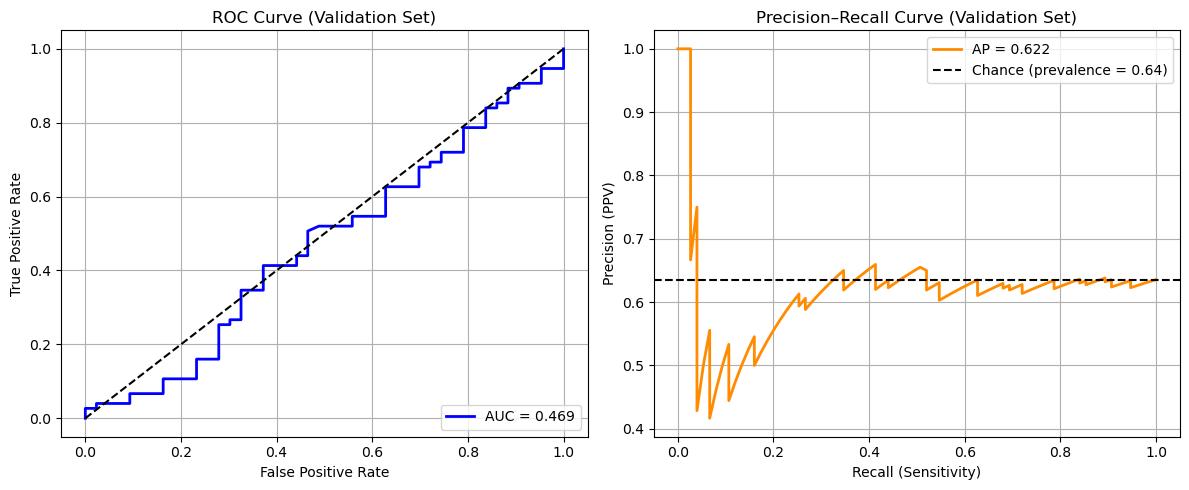

In [215]:
fpr, tpr, _ = roc_curve(y_tdBrain, y_proba)
roc_auc = auc(fpr, tpr)
prevalence = np.mean(y_tdBrain)
precision, recall, _ = precision_recall_curve(y_tdBrain, y_proba)
pr_auc = average_precision_score(y_tdBrain, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'AUC = {roc_auc:.3f}')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Validation Set)')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# PR
axes[1].plot(recall, precision, color='darkorange', lw=2, label=f'AP = {pr_auc:.3f}')
axes[1].axhline(y=prevalence, color='k', linestyle='--',
                label=f'Chance (prevalence = {prevalence:.2f})')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision–Recall Curve (Validation Set)')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.savefig('Final_TDBrain_ROC_PRC_validation.pdf')
plt.show()

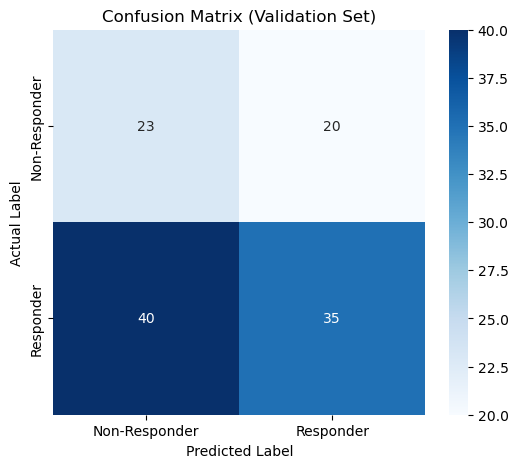

TN=23, FP=20, FN=40, TP=35


In [216]:
cm = confusion_matrix(y_tdBrain, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Responder', 'Responder'],
            yticklabels=['Non-Responder', 'Responder'])
plt.title('Confusion Matrix (Validation Set)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.savefig('Final_TDBrain_ConfuseMtrx_validation.pdf')
plt.show()

print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

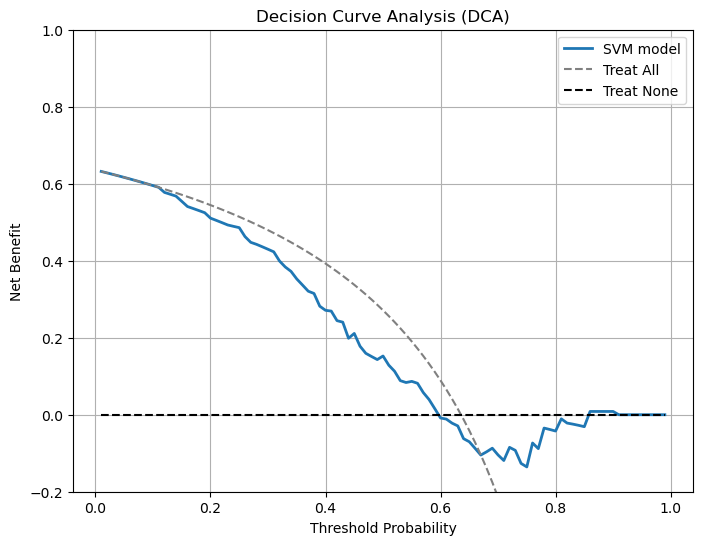

In [217]:
dca_df = decision_curve(y_tdBrain, y_proba,thresholds=np.linspace(0.01, 0.99, 99))

plt.figure(figsize=(8,6))
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_Model'], label='SVM model', lw=2)
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_All'], linestyle='--', color='gray', label='Treat All')
plt.plot(dca_df['Threshold'], dca_df['NetBenefit_None'], linestyle='--', color='black', label='Treat None')

plt.xlabel('Threshold Probability')
plt.ylabel('Net Benefit')
plt.title('Decision Curve Analysis (DCA)')
plt.ylim(-0.2, 1)
plt.legend()
plt.grid(True)
plt.show()
